# 06 — Dự đoán AQI ngày mai: thời tiết có giúp hơn "ngày mai giống hôm nay" không?

Notebook này làm **câu phụ 2** (dự đoán AQI ngày mai, W10) và **câu phụ 3** (cảnh báo ngày AQI ≥ 201, W11) của đề tài. Nó dùng bảng đã ghép ở `04_weather_merge`, các quy ước của `03_eda` và kết quả của `05_weather_correlation`. Hàm dùng chung ở `src/model_utils.py` (dùng lại `eda_utils.py` và `corr_utils.py`, không sửa hai file đó).

**Cách chạy:** *Kernel -> Restart & Run All*, từ thư mục `notebooks/`, sau khi đã chạy `01` và `04`. Hình lưu vào `reports/figures/` với tên `model_01_*` đến `model_05_*`. Cần `scikit-learn` và `statsmodels` (đã có trong `Requirements.txt`).

## Câu hỏi nghiên cứu của đề tài

> **Thời tiết (gió, nhiệt độ, độ ẩm, mưa, lớp biên khí quyển) có liên quan thế nào tới các ngày ô nhiễm nặng (AQI ≥ 201) ở 8 thành phố Ấn Độ giai đoạn 2015–2020, và có giúp cảnh báo trước một ngày các ngày đó tốt hơn việc cho rằng "ngày mai giống hôm nay" không, để cơ quan môi trường và người dân có cảnh báo sức khỏe sớm hơn?**

Notebook 05 trả lời phần "liên quan thế nào". Notebook này trả lời phần "có giúp cảnh báo trước một ngày tốt hơn không", bằng cách so **cùng một mô hình** với ba mức thông tin tăng dần, trên dữ liệu mô hình chưa từng thấy.

## Ý chính: baseline "ngày mai = hôm nay" rất mạnh, nên mọi con số phải đọc kèm nó

AQI có tự tương quan cao: hôm nay nặng thì ngày mai thường nặng. Vì vậy câu hỏi đúng không phải "mô hình có chính xác không" mà là **"mô hình hơn baseline bao nhiêu điểm, và hơn có chắc không"**. Mọi so sánh dưới đây đều có baseline đi kèm và khoảng tin cậy 95% bootstrap theo khối 14 ngày lịch.

## Quy ước

| Quy ước | Giá trị |
|---|---|
| Một dòng | một (thành phố, **ngày hôm nay** *t*); mục tiêu = AQI của ngày *t*+1 |
| Dữ liệu | `build_dataset()` (đọc `air_quality_8cities_weather.csv` và `weather_daily_8cities.csv`), khoảng chung 14/06/2017 – 01/07/2020; chỉ giữ dòng có **cả** AQI hôm nay và AQI ngày mai (không nội suy AQI, đúng quyết định ở bước 5 nhật ký làm sạch) |
| Chia | chia theo **ngày được dự đoán**. Train: đến 30/06/2019. **Test: 01/07/2019 – 29/02/2020** (trọn một mùa đông, 389 ngày nặng). 03–07/2020 (phong toả) tách riêng, không dùng để chọn gì |
| Chọn tham số | `TimeSeriesSplit` 4 lần **bên trong train**, cách nhau 2 ngày. Test chỉ mở một lần, ở Phần E |
| Mô hình chính | Ridge dự đoán **log AQI** ngày mai, báo lại theo điểm AQI. Mô hình cây (`HistGradientBoosting`) chỉ để so |
| Baseline | (1) trung bình theo thành phố; (2) trung vị cùng thành phố và cùng tháng (khí hậu); (3) **ngày mai = hôm nay** |
| Thời tiết | **chỉ đến hết hôm nay**. Thời tiết ngày mai chỉ xuất hiện ở "cận trên" (kịch bản dự báo hoàn hảo) |
| Chỉ số | hồi quy: MAE (chính), RMSE, R². Cảnh báo: recall, precision, F1, **không dùng accuracy** (W11) |
| Chống rò rỉ | mọi imputer, scaler, encoder và mô hình nằm trong `Pipeline`, chỉ fit trên train; có phép thử rò rỉ trực tiếp ở Phần A |



## 0. Setup

In [2]:
import sys, os
sys.path.append(os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor

from model_utils import (CITIES, ACCENT, NEUTRAL, LEVELS, LEVEL_NAME, NEXT_FEATS, POLL_FEATS, CAL_FEATS,
                         TRAIN_END, TEST_START, TEST_END, LOCK_START, vn, set_style, load, make_features, build_dataset,
                         make_pipe, time_cv, cv_score, oof_predict, mae, rmse, r2, baseline_preds, design_matrix, coef_table,
                         alert_metrics, best_threshold, calendar_blocks, block_boot, boot_mae_diff, boot_alert_diff, boot_alert_ci,
                         finish_chart, save_fig)
from corr_utils import load_with_weather, core_cities, boot_corr, block_id

pd.set_option("display.max_colwidth", None, "display.width", 200)
set_style()
ds = build_dataset()                                           # (thành phố, ngày hôm nay) -> AQI ngày mai, đã sắp theo thời gian
tr = ds[ds.split == "train"].reset_index(drop=True)
te = ds[ds.split == "test"].reset_index(drop=True)            # chỉ dùng ở Phần E trở đi
lk = ds[ds.split == "lockdown"].reset_index(drop=True)        # 03-07/2020, tách riêng (Phần H)

          dong  ngay_nang         tu        den
split                                          
lockdown   975         18 2020-03-01 2020-07-01
test      1947        389 2019-07-01 2020-02-29
train     5741       1432 2017-06-15 2019-06-30


# Phần A — Dữ liệu, cách chia và kiểm tra rò rỉ (W10: chia trước, mọi thứ khác sau)

## Ba mức đặc trưng cho cùng một mô hình

Nền chung cho cả ba mức: **thành phố** (biến giả, Delhi là mức tham chiếu) và **mùa** (sin, cos của ngày được dự đoán). Mùa được đưa vào ngay từ mức 1 để phần "thêm thời tiết" không chỉ là thay thế cho mùa (mùa là confounder lớn nhất ở notebook 05). Phần I kiểm tra lại bằng cách bỏ hai biến mùa.

| Mức | Thêm vào | Ý nghĩa |
|---|---|---|
| 1 | log AQI hôm nay, hôm qua, hôm kia, trung bình 7 ngày trước | "Chỉ lịch sử AQI" |
| 2 | log(1 + nồng độ) hôm nay của PM2.5, NO2, CO, SO2, O3 | Biết ô nhiễm hôm nay do chất nào |
| 3 | nhiệt độ, độ ẩm, áp suất (lệch so với trung bình 30 ngày trước), đổi áp suất so với hôm qua, tốc độ gió, gió Đông, gió Bắc, lớp biên, log(1 + mưa) hôm nay | Thời tiết **đến hết hôm nay** |
| Cận trên | + cùng 9 biến thời tiết của **ngày mai** | Dự báo thời tiết hoàn hảo; không dùng được trong thực tế, chỉ cho biết trần |

## Ba quyết định thiết kế (nêu rõ vì là lựa chọn của nhóm, và đều được quyết trên train, không nhìn test)

1. **Log AQI.** AQI cao dao động mạnh hơn AQI thấp (dạng phễu ở hình 1); mô hình trên log AQI bỏ được dạng phễu (W10, sửa 1).
2. **Áp suất thành độ lệch so với trung bình 30 ngày trước của chính thành phố.** Áp suất tuyệt đối gần như là "tên thành phố" (Bengaluru cao 914 m nên thấp hơn hẳn): VIF lên tới 192 khi để nguyên. Độ lệch chỉ dùng quá khứ nên không rò rỉ.
3. **Ô chất ô nhiễm đã nội suy ở bước làm sạch bị đặt lại NaN** rồi điền lùi tối đa 2 ngày. Nội suy tuyến tính dùng giá trị của các ngày *sau*, nên đưa vào đặc trưng của ngày *t* là để tương lai lọt vào quá khứ. Phần I cho thấy việc này gần như không đổi kết quả (nhưng vẫn làm cho đúng).

Giá trị còn thiếu (AQI các ngày trước, chất ô nhiễm) được điền bằng trung vị **của train** bên trong `Pipeline`, kèm cột báo thiếu.

In [3]:
rows = []
for c in CITIES:
    r = {"Thành phố": c}
    for s_, lab in [("train", "train"), ("test", "test"), ("lockdown", "03-07/2020")]:
        x = ds[(ds.City == c) & (ds.split == s_)]
        r[f"{lab}: n"], r[f"{lab}: ngày nặng"] = len(x), int(x.y_poor.sum())
    rows.append(r)
split_tab = pd.DataFrame(rows).set_index("Thành phố")
split_tab.loc["Cộng"] = split_tab.sum()
display(split_tab)
print(f"Tỉ lệ ngày AQI >= 201: train {tr.y_poor.mean()*100:.1f}%, test {te.y_poor.mean()*100:.1f}%, 03-07/2020 {lk.y_poor.mean()*100:.1f}%")
assert (len(tr), len(te), len(lk)) == (5741, 1947, 975) and (int(te.y_poor.sum()), int(lk.y_poor.sum())) == (389, 18)

,train: n,train: ngày nặng,test: n,test: ngày nặng,03-07/2020: n,03-07/2020: ngày nặng
Thành phố,,,,,,
Delhi,733,423,244,133,123,8
Gurugram,685,390,244,97,123,2
Lucknow,743,397,244,111,123,7
Jaipur,716,111,244,9,123,0
Bengaluru,737,2,244,0,123,0
Amritsar,650,84,239,29,114,1
Chennai,740,24,244,10,123,0
Hyderabad,737,1,244,0,123,0
Cộng,5741,1432,1947,389,975,18


Tỉ lệ ngày AQI >= 201: train 24.9%, test 20.0%, 03-07/2020 1.8%


In [4]:
# 1. thứ tự thời gian: ngày được dự đoán của train < test < phong toả, không giao nhau
assert tr.Date_target.max() < te.Date_target.min() and te.Date_target.max() < lk.Date_target.min()
assert (ds.Date_target == ds.Date + pd.Timedelta(days=1)).all()
# 2. các mức 1-3 không chứa thời tiết ngày mai
assert not set(NEXT_FEATS) & set(LEVELS["L3"])
# 3. phép thử rò rỉ trực tiếp: cắt toàn bộ dữ liệu sau ngày t, tính lại đặc trưng của ngày t, so với bản đầy đủ
full = make_features()
for cut in ["2018-12-01", "2019-11-15", "2020-01-10"]:
    cut = pd.Timestamp(cut)
    cutdf = make_features(as_of=cut)
    a = cutdf[cutdf.Date == cut].set_index("City")[LEVELS["L3"]].sort_index()
    b = full[full.Date == cut].set_index("City")[LEVELS["L3"]].sort_index()
    assert np.allclose(a.values, b.values, equal_nan=True), f"đặc trưng ngày {cut:%d/%m/%Y} phụ thuộc vào dữ liệu sau đó"
    assert cutdf[cutdf.Date == cut][NEXT_FEATS].isna().all().all()
print("Đạt cả 3 kiểm tra: đặc trưng của ngày t không dùng dữ liệu sau t.")

Đạt cả 3 kiểm tra: đặc trưng của ngày t không dùng dữ liệu sau t.


### Đọc bảng và kiểm tra

- Tập test có đúng **389 ngày nặng** trên 1.947 cặp (thành phố, ngày), trọn một mùa đông. Phong toả (03–07/2020) chỉ có **18** ngày nặng, nên chỉ dùng để xem sai số, không tính recall và precision.
- **Tỉ lệ ngày nặng giảm dần theo thời gian**: 24,9% (train) → 20,0% (test) → 1,8% (phong toả). Đây là xu hướng đã thấy ở `03_eda`. Hệ quả: ngưỡng chọn trên train có thể hơi "dễ" hơn so với test.
- Ba thành phố miền Nam gần như không có ngày nặng (Bengaluru, Hyderabad: 0; Chennai: 10 trong test). **Không đánh giá được cảnh báo ở đó**; chỉ có sai số AQI.
- Phép thử rò rỉ trực tiếp ở ô trên: cắt toàn bộ dữ liệu sau ngày *t*, tính lại đặc trưng của ngày *t*, so với bản đầy đủ. Hai bản **trùng từng giá trị** ở ba ngày thử, và các cột "thời tiết ngày mai" là NaN trong bản cắt. Đặc trưng của ngày *t* không dùng dữ liệu sau *t*.

# Phần B — Baseline và chọn tham số, chỉ trên validation (chưa đụng test)

`TimeSeriesSplit` cho 4 lần chia, mỗi lần fit trên quá khứ và đo trên khoảng liền sau. Bảng đầu cho thấy validation phủ cả mùa đông 2017–18, mùa mưa 2018 và mùa đông 2018–19. Bảng sau là MAE trung bình qua 4 lần chia (cột "± giữa các lần chia" là độ lệch chuẩn giữa các lần). Tham số `alpha` của Ridge và cấu hình cây được chọn bằng MAE này.

Đừng so MAE ở đây với MAE ở Phần E: validation (2017–2019) và test (07/2019–02/2020) là hai giai đoạn khác nhau.

In [5]:
folds = list(time_cv(len(tr)).split(tr))
fold_tab = pd.DataFrame([{"lần": k + 1, "fit trên ngày được dự đoán đến": f"{tr.iloc[a].Date_target.max():%d/%m/%Y}",
                          "validation": f"{tr.iloc[b].Date_target.min():%d/%m/%Y} - {tr.iloc[b].Date_target.max():%d/%m/%Y}",
                          "n fit": len(a), "n validation": len(b), "ngày nặng (validation)": int(tr.iloc[b].y_poor.sum())}
                         for k, (a, b) in enumerate(folds)]).set_index("lần")
display(fold_tab)

cv_base = {}
for a, b in folds:
    for name, p in baseline_preds(tr.iloc[a], tr.iloc[b]).items():
        cv_base.setdefault(name, []).append(mae(tr.iloc[b].y, p))

,fit trên ngày được dự đoán đến,validation,n fit,n validation,ngày nặng (validation)
lần,,,,,
1,18/11/2017,20/11/2017 - 19/04/2018,1133,1148,432
2,17/04/2018,19/04/2018 - 14/09/2018,2281,1148,147
3,12/09/2018,15/09/2018 - 06/02/2019,3429,1148,405
4,04/02/2019,07/02/2019 - 30/06/2019,4577,1148,209


In [6]:
ALPHAS = [0.1, 1, 10, 30, 100, 300]
cv_r = {lv: {a: cv_score(tr, f, lambda a=a, f=f: make_pipe(f, "ridge", alpha=a)) for a in ALPHAS} for lv, f in LEVELS.items()}
best_alpha = {lv: min(v, key=lambda a: v[a][0]) for lv, v in cv_r.items()}

HGB_GRID = [dict(max_depth=d, max_iter=n, learning_rate=0.05, min_samples_leaf=40) for d in (2, 3) for n in (100, 200)]
cv_h = {lv: [cv_score(tr, LEVELS[lv], lambda kw=kw, f=LEVELS[lv]: make_pipe(f, "hgb", **kw)) for kw in HGB_GRID] for lv in ["L1", "L2", "L3"]}
best_hgb = {lv: HGB_GRID[int(np.argmin([m for m, _ in v]))] for lv, v in cv_h.items()}

rows = [{"mô hình": k, "MAE validation": np.mean(v), "± giữa các lần chia": np.std(v), "tham số chọn": "—"} for k, v in cv_base.items()]
rows += [{"mô hình": f"Ridge {lv}: {LEVEL_NAME[lv]}", "MAE validation": cv_r[lv][best_alpha[lv]][0], "± giữa các lần chia": cv_r[lv][best_alpha[lv]][1],
          "tham số chọn": f"alpha = {best_alpha[lv]}"} for lv in LEVELS]
rows += [{"mô hình": f"Cây tăng cường (HGB) {lv}", "MAE validation": min(m for m, _ in cv_h[lv]), "± giữa các lần chia": cv_h[lv][int(np.argmin([m for m, _ in cv_h[lv]]))][1],
          "tham số chọn": f"depth {best_hgb[lv]['max_depth']}, {best_hgb[lv]['max_iter']} cây"} for lv in ["L1", "L2", "L3"]]
cv_tab = pd.DataFrame(rows).set_index("mô hình")
display(cv_tab.round(2))

,MAE validation,± giữa các lần chia,tham số chọn
mô hình,,,
Trung bình theo thành phố,60.49,10.42,—
Trung vị cùng tháng (khí hậu),55.82,15.75,—
Ngày mai = hôm nay,25.93,1.27,—
Ridge L1: Mức 1: chỉ AQI các ngày trước,25.52,1.41,alpha = 10
Ridge L2: Mức 2: + chất ô nhiễm hôm nay,23.73,1.50,alpha = 0.1
Ridge L3: Mức 3: + thời tiết đến hôm nay,22.33,1.16,alpha = 30
Ridge L4: Cận trên: + thời tiết ngày mai (dự báo hoàn hảo),22.16,1.21,alpha = 10
Cây tăng cường (HGB) L1,26.13,1.39,"depth 2, 100 cây"
Cây tăng cường (HGB) L2,22.84,1.03,"depth 2, 200 cây"


### Đọc bảng

- **"Ngày mai = hôm nay" là baseline rất mạnh**: MAE 25,9 điểm, so với 60,5 của "luôn đoán trung bình thành phố" và 55,8 của khí hậu cùng tháng. Hai baseline kia gần như vô dụng cho dự báo một ngày, vì AQI đổi theo ngày nhiều hơn theo mùa.
- **Mô hình chỉ có lịch sử AQI (mức 1) không hơn baseline**: 25,5 so với 25,9, chênh nhỏ hơn độ lệch giữa các lần chia (1,4). Thêm chất ô nhiễm (mức 2) xuống 23,7, thêm thời tiết (mức 3) xuống 22,3.
- Cây tăng cường cho kết quả **tương đương Ridge ở mức 3** (22,3 và 22,3). (Ở mức 2 cây hơn Ridge khoảng 0,9 điểm; ở mức 1 thì kém.) Với mức 3, validation không có lý do chọn cây, nên mô hình chính vẫn là Ridge, đúng như đã định từ trước (W10: "bắt đầu bằng mô hình tuyến tính, giữ nó nếu gần bằng").
- `alpha` chọn được nhỏ đến vừa (0,1 đến 30) và MAE gần như phẳng trong khoảng đó: kết quả không nhạy với lựa chọn này.

# Phần C — Chẩn đoán mô hình trước khi tin nó (W10: LINE, VIF, Cook)

Dùng `statsmodels` OLS trên **train**, mức 3, mục tiêu log AQI, chỉ các dòng đủ đặc trưng (để có hệ số diễn giải được; Ridge dùng để dự đoán thì điền trung vị trong `Pipeline`). Hình 1 so mô hình trên AQI với mô hình trên log AQI.

In [7]:
f3 = LEVELS["L3"]
cc = tr.dropna(subset=f3).reset_index(drop=True)                       # chỉ để diễn giải: OLS cần dòng đủ đặc trưng
X = design_matrix(cc, f3)
grp = ((cc.Date_target - cc.Date_target.min()).dt.days // 14).to_numpy()   # khối 14 ngày lịch, chung cho mọi thành phố
m_raw = sm.OLS(cc.y, X).fit()                                          # mục tiêu là AQI
m_log = sm.OLS(cc.y_log, X).fit()                                      # mục tiêu là log AQI
m_rob = sm.OLS(cc.y_log, X).fit(cov_type="cluster", cov_kwds={"groups": grp})   # cùng hệ số, sai số chuẩn bền theo khối
print(f"Dòng đủ đặc trưng: {len(cc)}/{len(tr)} ({len(cc)/len(tr)*100:.0f}%) · R² hiệu chỉnh trong mẫu (log AQI): {m_log.rsquared_adj:.3f} (KHÔNG phải thước đo chất lượng, xem Phần E)")

bp_raw, bp_log = het_breuschpagan(m_raw.resid, m_raw.model.exog), het_breuschpagan(m_log.resid, m_log.model.exog)
funnel = lambda m: pd.Series(np.abs(m.resid)).corr(pd.Series(m.fittedvalues), method="spearman")
acf1 = (cc.assign(r=m_log.resid.values).sort_values("Date").groupby("City", observed=True).r.apply(lambda s: s.autocorr(1)))
diag = pd.DataFrame({"mục tiêu = AQI": {"Spearman(|phần dư|, giá trị khớp)": funnel(m_raw), "Breusch-Pagan LM": bp_raw[0], "Durbin-Watson": durbin_watson(m_raw.resid)},
                     "mục tiêu = log AQI": {"Spearman(|phần dư|, giá trị khớp)": funnel(m_log), "Breusch-Pagan LM": bp_log[0], "Durbin-Watson": durbin_watson(m_log.resid)}})
display(diag.round(2))
print("Tự tương quan bậc 1 của phần dư (log AQI), theo thành phố:"); display(acf1.round(2).to_frame("ACF lag 1").T)

vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns).drop("const").sort_values(ascending=False)
print("VIF (W10: > 5 đáng xem, > 10 nghiêm trọng):"); display(vif.round(1).head(8).to_frame("VIF").T)
cook = m_log.get_influence().cooks_distance[0]
print(f"Cook's distance: {int((cook > 4/len(cook)).sum())} dòng vượt 4/n ({(cook > 4/len(cook)).mean()*100:.1f}%), lớn nhất {cook.max():.3f}")

Dòng đủ đặc trưng: 5118/5741 (89%) · R² hiệu chỉnh trong mẫu (log AQI): 0.891 (KHÔNG phải thước đo chất lượng, xem Phần E)


,mục tiêu = AQI,mục tiêu = log AQI
"Spearman(|phần dư|, giá trị khớp)",0.23,-0.03
Breusch-Pagan LM,408.51,311.11
Durbin-Watson,1.75,1.84


Tự tương quan bậc 1 của phần dư (log AQI), theo thành phố:


City,Delhi,Gurugram,Lucknow,Jaipur,Bengaluru,Amritsar,Chennai,Hyderabad
ACF lag 1,0.07,0.15,0.05,0.0,0.02,0.07,0.12,0.34


VIF (W10: > 5 đáng xem, > 10 nghiêm trọng):


,aqi_0,aqi_1,aqi_wk,aqi_2,temp_mean,pm25_0,doy_cos,blh_mean
VIF,14.5,12.2,10.9,9.9,8.8,8.3,7.4,6.2


Cook's distance: 343 dòng vượt 4/n (6.7%), lớn nhất 0.078


## Biểu đồ 1: log AQI bỏ được dạng phễu, nhưng phương sai vẫn chưa đều

Đã lưu reports\figures\model_01_residual_diagnostics.png


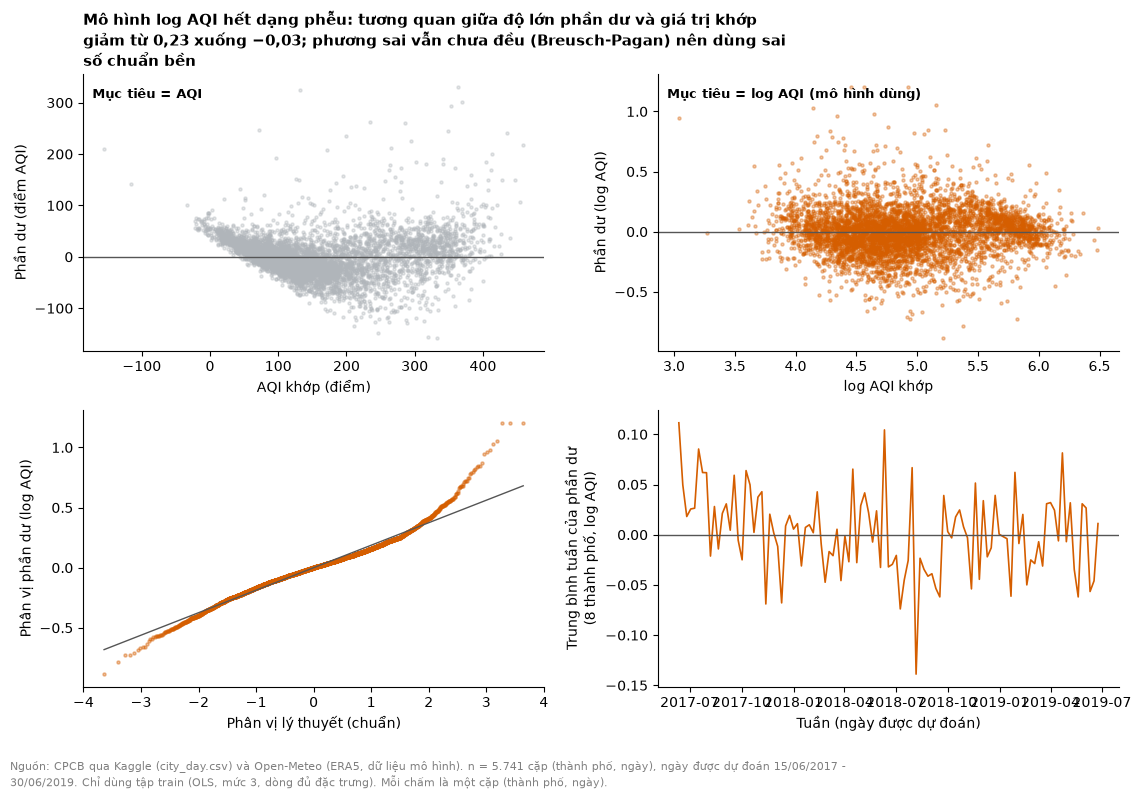

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 8))
ax = axes[0, 0]
ax.scatter(m_raw.fittedvalues, m_raw.resid, s=5, alpha=0.35, color=NEUTRAL)
ax.axhline(0, color="#555555", lw=1); ax.set_xlabel("AQI khớp (điểm)"); ax.set_ylabel("Phần dư (điểm AQI)")
ax.text(0.02, 0.95, "Mục tiêu = AQI", transform=ax.transAxes, va="top", fontsize=9, fontweight="bold")
ax = axes[0, 1]
ax.scatter(m_log.fittedvalues, m_log.resid, s=5, alpha=0.35, color=ACCENT)
ax.axhline(0, color="#555555", lw=1); ax.set_xlabel("log AQI khớp"); ax.set_ylabel("Phần dư (log AQI)")
ax.text(0.02, 0.95, "Mục tiêu = log AQI (mô hình dùng)", transform=ax.transAxes, va="top", fontsize=9, fontweight="bold")
ax = axes[1, 0]
(osm, osr), (slope, icpt, _) = stats.probplot(m_log.resid, dist="norm")
ax.scatter(osm, osr, s=5, alpha=0.4, color=ACCENT); ax.plot(osm, icpt + slope * osm, color="#555555", lw=1)
ax.set_xlabel("Phân vị lý thuyết (chuẩn)"); ax.set_ylabel("Phân vị phần dư (log AQI)")
ax = axes[1, 1]
wk = cc.assign(r=m_log.resid.values, w=cc.Date_target.dt.to_period("W").dt.start_time).groupby("w").r.mean()
ax.plot(wk.index, wk.values, color=ACCENT, lw=1.2); ax.axhline(0, color="#555555", lw=1)
ax.set_xlabel("Tuần (ngày được dự đoán)"); ax.set_ylabel("Trung bình tuần của phần dư\n(8 thành phố, log AQI)")
assert m_raw.fittedvalues.min() < 0, "Mô hình trên AQI không còn khớp ra AQI âm: sửa phần đọc biểu đồ 1"
assert funnel(m_raw) > 0.15 > abs(funnel(m_log)), "Dạng phễu đã đổi: sửa tiêu đề và phần đọc kết quả"
finish_chart(fig, axes[0, 0], f"Mô hình log AQI hết dạng phễu: tương quan giữa độ lớn phần dư và giá trị khớp giảm từ {vn(funnel(m_raw), 2)} xuống {vn(funnel(m_log), 2).replace('-', '−')}; "
                              f"phương sai vẫn chưa đều (Breusch-Pagan) nên dùng sai số chuẩn bền", tr,
             note="Chỉ dùng tập train (OLS, mức 3, dòng đủ đặc trưng). Mỗi chấm là một cặp (thành phố, ngày).")
save_fig(fig, "01_residual_diagnostics")


### Đọc biểu đồ 1 và bảng chẩn đoán

- **Linearity.** Mô hình trên AQI (trên trái) cho phần dư thành một dải cong và còn khớp ra **AQI âm** (đến khoảng −150), vô lý về mặt vật lý. Mô hình trên log AQI (trên phải) là đám mây không có hình dạng quanh 0: đạt.
- **Equal variance.** Trên AQI, độ lớn phần dư tăng theo giá trị khớp (Spearman 0,23): dạng phễu. Trên log AQI còn −0,03: phễu biến mất. **Nhưng Breusch-Pagan vẫn bác bỏ phương sai đều** (LM 311, từ 409) vì phương sai còn khác nhau theo thành phố và mùa. Hệ quả (W10): hệ số không lệch nhưng sai số chuẩn thì sai, nên mọi khoảng tin cậy ở Phần D dùng **sai số chuẩn bền theo khối 14 ngày**, không dùng p-value mặc định.
- **Normality.** QQ-plot (dưới trái) khá thẳng ở giữa, **đuôi phải nặng**: có những ngày AQI tăng vọt mà mô hình không báo trước (phần dư log lên tới +1,2, tức gấp ~3 lần dự đoán). Đây là tiêu chí ít quan trọng nhất của LINE, nhưng là thông tin thật: mô hình thường **hụt ở các đợt tăng đột ngột**.
- **Independence.** Durbin-Watson 1,84 và tự tương quan bậc 1 của phần dư chỉ 0,00 đến 0,15 ở bảy thành phố: lịch sử AQI đã hấp thụ gần hết tự tương quan. **Ngoại lệ Hyderabad (0,34)**: ở đó mô hình còn bỏ sót quán tính. Hình dưới phải không có xu hướng hay sóng dài.
- **VIF.** Bốn biến AQI trễ có VIF 9,9 đến 14,5 (chúng vốn là cùng một đại lượng đo ở các ngày kề nhau), nhiệt độ 8,8 và PM2.5 8,3. Hệ quả: **không diễn giải từng hệ số của AQI trễ riêng lẻ** (hệ số của AQI hôm qua âm chỉ vì nó đang "sửa" hệ số của hôm nay). Ridge xử lý được điều này khi dự đoán.
- **Cook's distance.** Lớn nhất 0,078, không có dòng nào chi phối mô hình (343 dòng vượt 4/n là bình thường khi n lớn và phần dư có đuôi nặng).
- **R² hiệu chỉnh trong mẫu 0,89 không phải thước đo chất lượng** (W10): phần lớn là do AQI hôm nay đã "giải thích" AQI ngày mai. Chất lượng chỉ đọc ở Phần E, trên test và so với baseline.

# Phần D — Diễn giải hệ số: mỗi hệ số một câu (W10)

Mỗi câu đủ bốn nghĩa vụ của W10: **"đi cùng với"** (không "gây ra"), **"giữ các biến còn lại trong mô hình không đổi"** (biến chưa đo thì không được giữ), **đơn vị**, và **khoảng đã quan sát** của train (mô hình không có gì để nói ngoài khoảng đó). Khoảng tin cậy 95% dùng sai số chuẩn bền theo khối 14 ngày (kết luận của Phần C). Vì mục tiêu là log AQI, hệ số được đổi thành **% thay đổi của AQI ngày mai**.

In [9]:
ct = coef_table(m_rob, cc, f3)
show = ct.assign(**{"β": ct["β (log AQI)"].round(3), "p (khối)": ct["p (khối)"].round(3)})[["biến", "β", "p (khối)", "diễn giải"]]
display(show.set_index("biến"))

,β,p (khối),diễn giải
biến,,,
aqi_0,0.376,0.000,"Khi AQI hôm nay cao hơn 10%, AQI ngày mai đi cùng với +3,6% (+3,0% đến +4,3%, KTC 95%), giữ các biến còn lại trong mô hình không đổi; chỉ trong khoảng AQI đã quan sát 26 đến 869."
aqi_1,-0.073,0.000,"Khi AQI hôm qua cao hơn 10%, AQI ngày mai đi cùng với −0,7% (−1,0% đến −0,3%, KTC 95%), giữ các biến còn lại trong mô hình không đổi; chỉ trong khoảng AQI đã quan sát 26 đến 732."
aqi_2,0.049,0.015,"Khi AQI hôm kia cao hơn 10%, AQI ngày mai đi cùng với +0,5% (+0,1% đến +0,8%, KTC 95%), giữ các biến còn lại trong mô hình không đổi; chỉ trong khoảng AQI đã quan sát 26 đến 891."
aqi_wk,0.113,0.000,"Khi AQI trung bình 7 ngày trước cao hơn 10%, AQI ngày mai đi cùng với +1,1% (+0,7% đến +1,5%, KTC 95%), giữ các biến còn lại trong mô hình không đổi; chỉ trong khoảng AQI đã quan sát 41 đến 589."
pm25_0,0.305,0.000,"Khi PM2.5 hôm nay cao hơn 10% (tính trên 1 + nồng độ), AQI ngày mai đi cùng với +3,0% (+2,5% đến +3,4%, KTC 95%), giữ các biến còn lại trong mô hình không đổi; chỉ trong khoảng đã quan sát 1,7 đến 639,2 µg/m³."
no2_0,0.019,0.062,"Khi NO2 hôm nay cao hơn 10% (tính trên 1 + nồng độ), AQI ngày mai đi cùng với +0,2% (0,0% đến +0,4%, KTC 95%), giữ các biến còn lại trong mô hình không đổi; chỉ trong khoảng đã quan sát 0,0 đến 203,4 µg/m³."
co_0,0.047,0.015,"Khi CO hôm nay cao hơn 10% (tính trên 1 + nồng độ), AQI ngày mai đi cùng với +0,4% (+0,1% đến +0,8%, KTC 95%), giữ các biến còn lại trong mô hình không đổi; chỉ trong khoảng đã quan sát 0,0 đến 16,0 mg/m³."
so2_0,0.001,0.912,"Khi SO2 hôm nay cao hơn 10% (tính trên 1 + nồng độ), AQI ngày mai đi cùng với 0,0% (−0,1% đến +0,2%, KTC 95%), giữ các biến còn lại trong mô hình không đổi; chỉ trong khoảng đã quan sát 0,5 đến 67,3 µg/m³."
o3_0,0.034,0.000,"Khi O3 hôm nay cao hơn 10% (tính trên 1 + nồng độ), AQI ngày mai đi cùng với +0,3% (+0,2% đến +0,5%, KTC 95%), giữ các biến còn lại trong mô hình không đổi; chỉ trong khoảng đã quan sát 0,2 đến 135,7 µg/m³."


### Đọc bảng

- **Ba biến thời tiết có khoảng tin cậy loại trừ 0 và dễ giải thích:** độ ẩm cao hơn đi cùng AQI ngày mai thấp hơn (−1,2% mỗi 10 điểm %), gió mạnh hơn đi cùng AQI thấp hơn (−1,9% mỗi m/s) và ngày có mưa đi cùng AQI thấp hơn nhiều nhất (−9,2% với 10 mm so với không mưa). Hướng khớp với kết quả của notebook 05 (độ ẩm nhất quán nhất; mưa rửa trôi).
- **Gió hướng Đông** đi cùng AQI **cao** hơn (+1,8% mỗi m/s), nhưng gió Bắc thì không tách khỏi 0. Hướng gió thay đổi theo thành phố, nên đây là gợi ý cần kiểm tra theo từng thành phố, chưa phải kết luận.
- **Nhiệt độ, lớp biên khí quyển, áp suất và mức đổi áp suất không tách khỏi 0** sau khi đã giữ AQI hôm nay và chất ô nhiễm. Lớp biên (+0,1% mỗi 100 m, từ −0,5% đến +0,7%) tiếp tục **không ủng hộ** trực giác "lớp biên thấp thì ô nhiễm bị nén lại", cùng kết luận với notebook 05.
- Các hệ số là **điều kiện** theo AQI hôm nay và chất ô nhiễm hôm nay. Thời tiết có thể đã tác động lên chúng, nên hệ số thời tiết ở đây nhỏ hơn tương quan thô ở notebook 05. Hai con số không mâu thuẫn, chúng trả lời hai câu hỏi khác nhau.
- Trong các chất ô nhiễm, PM2.5 có hệ số lớn nhất (+3,0% khi PM2.5 hôm nay cao hơn 10%), hợp lý vì PM2.5 thường là chất quyết định AQI ở các thành phố này. Hệ số của SO2 và NO2 không tách khỏi 0.
- Hệ số thành phố chỉ có nghĩa so với Delhi (mức tham chiếu).

# Phần E — Mở tập test (một lần duy nhất)

Từ đây mới dùng tập test (01/07/2019 – 29/02/2020). Mọi quyết định (đặc trưng, log, `alpha`, cấu hình cây) đã chốt ở các phần trên. Mô hình fit trên **toàn bộ train**, dự đoán test, đổi lại về điểm AQI bằng `exp`. Khoảng tin cậy của **hiệu số MAE** lấy bằng bootstrap theo khối 14 ngày lịch (ngày kề nhau, và các thành phố cùng ngày, đều không độc lập).

In [10]:
pred_te, pred_lk, fitted = {}, {}, {}
for lv, f in LEVELS.items():
    m = make_pipe(f, "ridge", alpha=best_alpha[lv]).fit(tr[f + ["City"]], tr.y_log)      # fit trên train, một lần
    fitted[f"Ridge {lv}"] = m
    pred_te[f"Ridge {lv}"], pred_lk[f"Ridge {lv}"] = np.exp(m.predict(te[f + ["City"]])), np.exp(m.predict(lk[f + ["City"]]))
for lv in ["L1", "L2", "L3"]:
    f = LEVELS[lv]
    m = make_pipe(f, "hgb", **best_hgb[lv]).fit(tr[f + ["City"]], tr.y_log)
    pred_te[f"HGB {lv}"], pred_lk[f"HGB {lv}"] = np.exp(m.predict(te[f + ["City"]])), np.exp(m.predict(lk[f + ["City"]]))
pred_te.update(baseline_preds(tr, te)); pred_lk.update(baseline_preds(tr, lk))
PERSIST = "Ngày mai = hôm nay"
order = ["Trung bình theo thành phố", "Trung vị cùng tháng (khí hậu)", PERSIST, "Ridge L1", "Ridge L2", "Ridge L3", "Ridge L4", "HGB L1", "HGB L2", "HGB L3"]

def score_table(d, preds):
    heavy = d.y_poor.to_numpy()
    rows = {}
    for k in order:
        p = preds[k]
        rows[k] = {"MAE": mae(d.y, p), "RMSE": rmse(d.y, p), "R²": r2(d.y, p),
                   "MAE ngày nặng": mae(d.y[heavy], p[heavy]) if heavy.any() else np.nan, "MAE ngày còn lại": mae(d.y[~heavy], p[~heavy])}
    t = pd.DataFrame(rows).T
    t["giảm MAE so với 'hôm nay'"] = (1 - t.MAE / t.loc[PERSIST, "MAE"]) * 100
    return t
test_tab = score_table(te, pred_te)
display(test_tab.round(2).rename(columns={"giảm MAE so với 'hôm nay'": "giảm MAE so với 'hôm nay' (%)"}))

,MAE,RMSE,R²,MAE ngày nặng,MAE ngày còn lại,giảm MAE so với 'hôm nay' (%)
Trung bình theo thành phố,64.47,85.15,0.26,95.12,56.82,-174.74
Trung vị cùng tháng (khí hậu),43.41,64.28,0.58,63.11,38.49,-84.97
Ngày mai = hôm nay,23.47,37.61,0.86,47.46,17.48,0.00
Ridge L1,22.94,36.00,0.87,46.58,17.03,2.25
Ridge L2,20.92,31.89,0.90,42.10,15.63,10.86
Ridge L3,19.52,30.23,0.91,39.77,14.46,16.82
Ridge L4,19.08,29.62,0.91,39.14,14.08,18.67
HGB L1,23.47,37.02,0.86,49.44,16.99,-0.03
HGB L2,19.02,29.46,0.91,36.50,14.66,18.93
HGB L3,18.03,28.55,0.92,35.07,13.77,23.19


In [11]:
bl = calendar_blocks(te.Date_target)
err = lambda k: np.abs(te.y.to_numpy() - pred_te[k])
pairs = [("Ridge L1", PERSIST), ("Ridge L2", "Ridge L1"), ("Ridge L3", "Ridge L2"), ("Ridge L3", "Ridge L1"), ("Ridge L3", PERSIST),
         ("Ridge L4", "Ridge L3"), ("HGB L3", "Ridge L3")]
rows = []
for a_, b_ in pairs:
    d_, lo, hi = boot_mae_diff(bl, err(a_), err(b_))
    rows.append({"so sánh (A trừ B)": f"{a_}  −  {b_}", "ΔMAE (điểm AQI)": d_, "KTC 95% thấp": lo, "KTC 95% cao": hi,
                 "kết luận": "A tốt hơn B" if hi < 0 else "A kém hơn B" if lo > 0 else "chưa tách khỏi 0"})
mdiff = {(a_, b_): (r["ΔMAE (điểm AQI)"], r["KTC 95% thấp"], r["KTC 95% cao"]) for (a_, b_), r in zip(pairs, rows)}
mae_diff = pd.DataFrame(rows).set_index("so sánh (A trừ B)")
display(mae_diff.round(2))

,ΔMAE (điểm AQI),KTC 95% thấp,KTC 95% cao,kết luận
so sánh (A trừ B),,,,
Ridge L1 − Ngày mai = hôm nay,-0.53,-1.19,0.08,chưa tách khỏi 0
Ridge L2 − Ridge L1,-2.02,-3.06,-1.05,A tốt hơn B
Ridge L3 − Ridge L2,-1.40,-1.93,-0.93,A tốt hơn B
Ridge L3 − Ridge L1,-3.42,-4.56,-2.30,A tốt hơn B
Ridge L3 − Ngày mai = hôm nay,-3.95,-5.40,-2.56,A tốt hơn B
Ridge L4 − Ridge L3,-0.43,-0.62,-0.26,A tốt hơn B
HGB L3 − Ridge L3,-1.49,-2.21,-0.70,A tốt hơn B


## Biểu đồ 2: thêm chất ô nhiễm rồi thời tiết giảm sai số trên tập test

Đã lưu reports\figures\model_02_mae_by_model.png


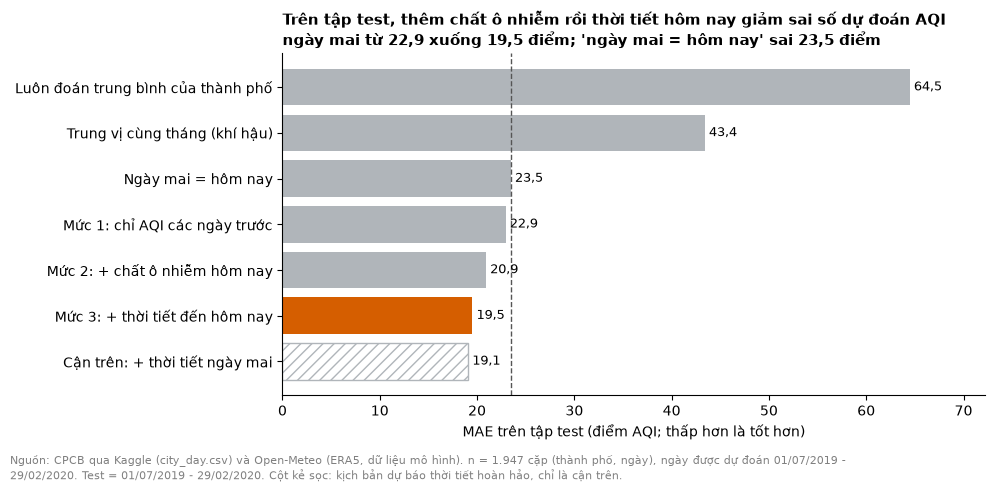

In [12]:
labels = {"Trung bình theo thành phố": "Luôn đoán trung bình của thành phố", "Trung vị cùng tháng (khí hậu)": "Trung vị cùng tháng (khí hậu)", PERSIST: "Ngày mai = hôm nay",
          "Ridge L1": "Mức 1: chỉ AQI các ngày trước", "Ridge L2": "Mức 2: + chất ô nhiễm hôm nay", "Ridge L3": "Mức 3: + thời tiết đến hôm nay",
          "Ridge L4": "Cận trên: + thời tiết ngày mai"}
keys = list(labels)
vals = [test_tab.loc[k, "MAE"] for k in keys]
fig, ax = plt.subplots(figsize=(10, 4.9))
cols = [NEUTRAL] * len(keys); cols[keys.index("Ridge L3")] = ACCENT
bars = ax.barh(range(len(keys)), vals, color=cols)
bars[-1].set_hatch("///"); bars[-1].set_facecolor("white"); bars[-1].set_edgecolor(NEUTRAL)
ax.bar_label(bars, labels=[vn(v, 1) for v in vals], padding=3, fontsize=9)
ax.axvline(test_tab.loc[PERSIST, "MAE"], color="#555555", lw=1, ls="--")
ax.set_yticks(range(len(keys))); ax.set_yticklabels([labels[k] for k in keys]); ax.invert_yaxis()
ax.set_xlabel("MAE trên tập test (điểm AQI; thấp hơn là tốt hơn)"); ax.set_xlim(0, max(vals) * 1.12)
m_p, m1, m2, m3, m4 = (test_tab.loc[k, "MAE"] for k in [PERSIST, "Ridge L1", "Ridge L2", "Ridge L3", "Ridge L4"])
assert m4 < m3 < m2 < m1 < m_p, "Thứ tự các mức đã đổi: sửa tiêu đề và phần đọc kết quả"
finish_chart(fig, ax, f"Trên tập test, thêm chất ô nhiễm rồi thời tiết hôm nay giảm sai số dự đoán AQI ngày mai từ {vn(m1, 1)} xuống {vn(m3, 1)} điểm; "
                      f"'ngày mai = hôm nay' sai {vn(m_p, 1)} điểm", te,
             note="Test = 01/07/2019 - 29/02/2020. Cột kẻ sọc: kịch bản dự báo thời tiết hoàn hảo, chỉ là cận trên.")
save_fig(fig, "02_mae_by_model")

### Đọc bảng test và bảng hiệu số

- **"Ngày mai = hôm nay" sai 23,5 điểm AQI** (R² 0,86). Mô hình mức 3 sai **19,5** (R² 0,91), tức **giảm 16,8%**, hiệu số −3,95 điểm (khoảng tin cậy −5,4 đến −2,6): tách khỏi 0 rõ ràng. RMSE cũng giảm từ 37,6 xuống 30,2.
- **Hai bậc thang tiếp theo đều tách khỏi 0:** mức 1 → mức 2 (thêm chất ô nhiễm) −2,0; mức 2 → mức 3 (thêm thời tiết) −1,4 (khoảng tin cậy −1,9 đến −0,9). **Riêng phần thời tiết giảm khoảng 1,4 điểm, tức khoảng 7% MAE của mức 2.** Khiêm tốn, đúng như dự đoán từ notebook 05 ("gió và lớp biên yếu hơn kỳ vọng").
- **Mô hình chỉ có lịch sử AQI (mức 1) chưa tách khỏi baseline** (−0,53; −1,2 đến +0,1). Phần lớn lợi thế so với "ngày mai = hôm nay" đến từ **chất ô nhiễm và thời tiết**, không phải từ việc xử lý lịch sử AQI khéo hơn.
- **Cận trên (biết trước thời tiết ngày mai) chỉ tốt hơn mức 3 thêm 0,43 điểm** (−0,62 đến −0,26). Nghĩa là nếu sau này có dự báo thời tiết thật, lợi ích thêm là nhỏ: thông tin quan trọng đã nằm ở trạng thái hôm nay.
- **Trên ngày nặng, sai số lớn hơn nhiều** (MAE 47,5 với "hôm nay" và 39,8 với mức 3, so với 17,5 và 14,5 ở ngày còn lại): mô hình giảm được sai số ở cả hai nhóm nhưng ngày nặng vẫn là chỗ khó nhất, đúng chỗ người dân cần cảnh báo.
- **Cây tăng cường mức 3 tốt hơn Ridge mức 3 trên test** (18,0 so với 19,5; hiệu số −1,5, khoảng tin cậy −2,2 đến −0,7), dù trên validation hai mô hình hoà. Có hai cách đọc: quan hệ phi tuyến có thật, hoặc test có đặc điểm riêng. **Đừng đổi mô hình chính sau khi đã thấy test**: làm vậy test không còn là test. Nên báo cả hai trong bảng, giữ Ridge làm mô hình chính vì giải thích được (W10), và nói rõ cây hơn ~1,5 điểm.

## Biểu đồ 3: sai số theo thành phố, so với 'ngày mai = hôm nay'

,n,ngày nặng,MAE hôm nay,MAE mức 1,MAE mức 3,giảm so với 'hôm nay' (%)
Thành phố,,,,,,
Delhi,244,133,36.7,37.1,29.3,20.2
Lucknow,244,111,29.1,29.1,22.7,22.1
Gurugram,244,97,37.1,36.8,30.1,18.9
Amritsar,239,29,29.0,26.7,24.4,15.9
Chennai,244,10,19.4,18.6,17.0,12.4
Jaipur,244,9,16.4,15.7,15.2,7.3
Bengaluru,244,0,8.7,8.2,7.9,9.1
Hyderabad,244,0,11.4,11.4,9.7,14.9


Đã lưu reports\figures\model_03_mae_by_city.png


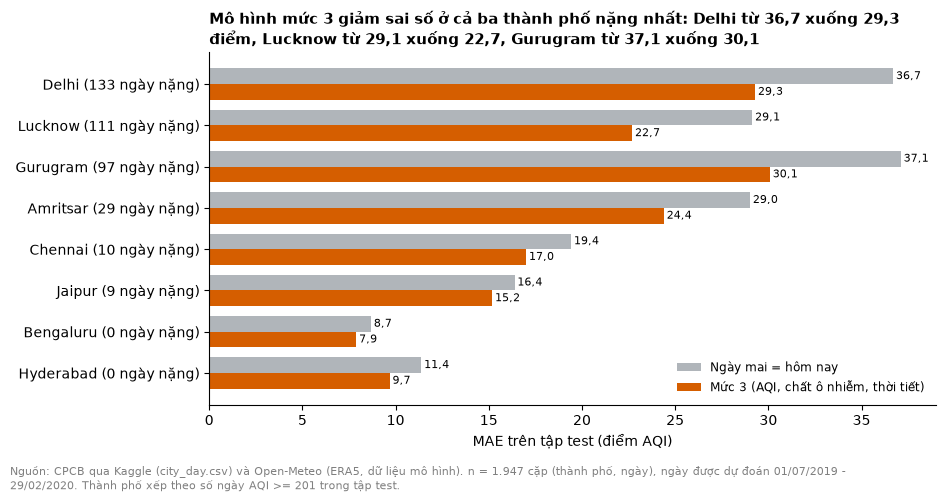

In [13]:
byc = []
for c in CITIES:
    mk = (te.City == c).to_numpy()
    byc.append({"Thành phố": c, "n": int(mk.sum()), "ngày nặng": int(te.y_poor[mk].sum()),
                "MAE hôm nay": mae(te.y[mk], pred_te[PERSIST][mk]), "MAE mức 1": mae(te.y[mk], pred_te["Ridge L1"][mk]),
                "MAE mức 3": mae(te.y[mk], pred_te["Ridge L3"][mk])})
byc = pd.DataFrame(byc).sort_values("ngày nặng", ascending=False).set_index("Thành phố")
byc["giảm so với 'hôm nay' (%)"] = (1 - byc["MAE mức 3"] / byc["MAE hôm nay"]) * 100
display(byc.round(1))

fig, ax = plt.subplots(figsize=(9.5, 5))
yy, h = np.arange(len(byc)), 0.38
b1 = ax.barh(yy - h / 2, byc["MAE hôm nay"], h, color=NEUTRAL, label="Ngày mai = hôm nay")
b2 = ax.barh(yy + h / 2, byc["MAE mức 3"], h, color=ACCENT, label="Mức 3 (AQI, chất ô nhiễm, thời tiết)")
ax.bar_label(b1, labels=[vn(v, 1) for v in byc["MAE hôm nay"]], padding=2, fontsize=8); ax.bar_label(b2, labels=[vn(v, 1) for v in byc["MAE mức 3"]], padding=2, fontsize=8)
ax.set_yticks(yy); ax.set_yticklabels([f"{c} ({n} ngày nặng)" for c, n in zip(byc.index, byc["ngày nặng"])]); ax.invert_yaxis()
ax.set_xlabel("MAE trên tập test (điểm AQI)"); ax.legend(frameon=False, loc="lower right", fontsize=8.5)
dl, gu, lu = byc.loc["Delhi"], byc.loc["Gurugram"], byc.loc["Lucknow"]
south = byc.loc[["Bengaluru", "Chennai", "Hyderabad"]]
assert all(byc.loc[c, "MAE mức 3"] < byc.loc[c, "MAE hôm nay"] for c in ["Delhi", "Gurugram", "Lucknow"]), "Mức 3 không còn tốt hơn ở ba thành phố nặng: sửa tiêu đề"
finish_chart(fig, ax, f"Mô hình mức 3 giảm sai số ở cả ba thành phố nặng nhất: Delhi từ {vn(dl['MAE hôm nay'], 1)} xuống {vn(dl['MAE mức 3'], 1)} điểm, "
                      f"Lucknow từ {vn(lu['MAE hôm nay'], 1)} xuống {vn(lu['MAE mức 3'], 1)}, Gurugram từ {vn(gu['MAE hôm nay'], 1)} xuống {vn(gu['MAE mức 3'], 1)}", te,
             note="Thành phố xếp theo số ngày AQI >= 201 trong tập test.")
save_fig(fig, "03_mae_by_city")

### Đọc biểu đồ 3

- Mức giảm sai số cùng chiều ở **cả 8 thành phố** (7% đến 22%), lớn nhất ở ba thành phố nặng nhất (Delhi 20%, Lucknow 22%, Gurugram 19%).
- Sai số tuyệt đối ở miền Nam (Bengaluru, Hyderabad, Chennai) nhỏ hơn vì AQI ở đó thấp (xem `03_eda`); **đừng đọc nó như "mô hình tốt hơn ở miền Nam"**. Đơn vị so sánh công bằng giữa các thành phố là mức giảm so với baseline của chính thành phố đó.
- Delhi và Gurugram có thời tiết gần trùng nhau (xem `04_weather_merge`), nên hai kết quả gần giống nhau ở đây **không phải hai bằng chứng độc lập**. Phần I bỏ Gurugram để kiểm tra.

# Phần F — Cảnh báo ngày AQI ≥ 201 trước một ngày (W11)

## Chọn chỉ số và ngưỡng trước khi nhìn kết quả

- **Chỉ số chính: recall, ràng buộc bởi precision.** Bỏ sót một ngày nặng nghĩa là người dân không được cảnh báo sức khỏe; báo nhầm một ngày chỉ tốn một lần cảnh báo thừa. Giống sàng lọc bệnh (W11): recall quan trọng hơn, nhưng precision thấp quá thì cảnh báo mất uy tín. Đây là **một nhận định về chi phí**, không phải sự thật toán học; hình 4 cho phép người ra quyết định chọn điểm khác.
- **Ngưỡng:** áp ngưỡng lên **AQI dự đoán**, chọn bằng **F2** (recall nặng gấp đôi precision) trên các dòng validation của `TimeSeriesSplit` (dự đoán "ngoài mẫu" của train). Ngưỡng **không** chọn trên test (W11: chọn trên test là rò rỉ dưới dạng hấp dẫn nhất).
- **Công bằng với baseline:** "ngày mai = hôm nay" cũng được chọn ngưỡng theo đúng quy tắc và đúng các dòng đó. Bảng cũng báo ngưỡng 201 mặc định (baseline theo nghĩa đen).
- **Không dùng accuracy.** Mô hình "không bao giờ cảnh báo" đúng 80% số ngày trong test và có recall bằng 0 (hàng đầu của bảng).

In [14]:
y_tr = tr.y_poor.to_numpy()
oof = {lv: oof_predict(tr, f, lambda f=f, lv=lv: make_pipe(f, "ridge", alpha=best_alpha[lv])) for lv, f in LEVELS.items()}
idx = oof["L1"][0]
assert all((oof[lv][0] == idx).all() for lv in LEVELS)               # mọi ngưỡng được chọn trên CÙNG các dòng validation
thr = {lv: best_threshold(y_tr[idx], oof[lv][1])[0] for lv in LEVELS}
thr_p = best_threshold(y_tr[idx], tr.AQI.to_numpy()[idx])[0]           # 'ngày mai = hôm nay' cũng được chọn ngưỡng công bằng như mô hình
oof_h = oof_predict(tr, LEVELS["L3"], lambda: make_pipe(LEVELS["L3"], "hgb", **best_hgb["L3"]))
assert (oof_h[0] == idx).all(); thr_h = best_threshold(y_tr[idx], oof_h[1])[0]
print(f"Validation: {len(idx)} dòng, {int(y_tr[idx].sum())} ngày nặng. Ngưỡng chọn bằng F2 (recall nặng gấp đôi precision):")
print({"Ngày mai = hôm nay": thr_p, **{f"Ridge {lv}": thr[lv] for lv in LEVELS}})

Validation: 4592 dòng, 1193 ngày nặng. Ngưỡng chọn bằng F2 (recall nặng gấp đôi precision):
{'Ngày mai = hôm nay': 160.0, 'Ridge L1': 169.0, 'Ridge L2': 165.0, 'Ridge L3': 166.0, 'Ridge L4': 164.0}


## Bảng cảnh báo trên tập test (ngưỡng 201 và ngưỡng chọn trên validation)

In [15]:
y_te = te.y_poor.to_numpy()
aq_te = te.AQI.to_numpy()
flags = {"Không bao giờ cảnh báo": np.zeros(len(te), bool),
         f"{PERSIST} (ngưỡng 201)": aq_te >= 201, f"{PERSIST} (ngưỡng {thr_p:.0f})": aq_te >= thr_p}
for lv in LEVELS:
    flags[f"Ridge {lv} (ngưỡng 201)"] = pred_te[f"Ridge {lv}"] >= 201
    flags[f"Ridge {lv} (ngưỡng {thr[lv]:.0f})"] = pred_te[f"Ridge {lv}"] >= thr[lv]
flags["HGB L3 (ngưỡng 201)"], flags[f"HGB L3 (ngưỡng {thr_h:.0f})"] = pred_te["HGB L3"] >= 201, pred_te["HGB L3"] >= thr_h

def alert_row(flag, ci=True):
    m = alert_metrics(y_te, flag)
    r = {"recall": m["recall"], "precision": m["precision"], "F1": m["F1"], "số cảnh báo": m["n_canh_bao"], "bỏ sót": m["FN"], "báo nhầm": m["FP"]}
    if ci and m["TP"] > 0:
        _, lo, hi = boot_alert_ci(bl, y_te, flag, "recall"); r["recall KTC95%"] = f"[{lo:.2f}; {hi:.2f}]"
        _, lo, hi = boot_alert_ci(bl, y_te, flag, "precision"); r["precision KTC95%"] = f"[{lo:.2f}; {hi:.2f}]"
    return r
alert_tab = pd.DataFrame({k: alert_row(v) for k, v in flags.items()}).T
display(alert_tab.round(3))

,recall,precision,F1,số cảnh báo,bỏ sót,báo nhầm,recall KTC95%,precision KTC95%
Không bao giờ cảnh báo,0.0,NaN,0.0,0.0,389.0,0.0,NaN,NaN
Ngày mai = hôm nay (ngưỡng 201),0.856041,0.84949,0.852753,392,56,59,[0.80; 0.89],[0.79; 0.89]
Ngày mai = hôm nay (ngưỡng 160),0.96144,0.723404,0.825607,517,15,143,[0.93; 0.98],[0.64; 0.78]
Ridge L1 (ngưỡng 201),0.874036,0.86514,0.869565,393,49,53,[0.82; 0.91],[0.80; 0.91]
Ridge L1 (ngưỡng 169),0.956298,0.78481,0.862109,474,17,102,[0.93; 0.97],[0.71; 0.84]
Ridge L2 (ngưỡng 201),0.871465,0.887435,0.879377,382,50,43,[0.82; 0.90],[0.83; 0.93]
Ridge L2 (ngưỡng 165),0.971722,0.769857,0.859091,491,11,113,[0.95; 0.98],[0.69; 0.82]
Ridge L3 (ngưỡng 201),0.88946,0.896373,0.892903,386,43,40,[0.84; 0.93],[0.83; 0.94]
Ridge L3 (ngưỡng 166),0.969152,0.769388,0.857793,490,12,113,[0.95; 0.98],[0.70; 0.82]
Ridge L4 (ngưỡng 201),0.904884,0.904884,0.904884,389,37,37,[0.86; 0.94],[0.85; 0.94]


## So sánh có khoảng tin cậy (bootstrap theo khối 14 ngày lịch)

In [16]:
K = {"p201": f"{PERSIST} (ngưỡng 201)", "pt": f"{PERSIST} (ngưỡng {thr_p:.0f})",
     "L1t": f"Ridge L1 (ngưỡng {thr['L1']:.0f})", "L2t": f"Ridge L2 (ngưỡng {thr['L2']:.0f})", "Ht": f"HGB L3 (ngưỡng {thr_h:.0f})", "L3t": f"Ridge L3 (ngưỡng {thr['L3']:.0f})", "L3_201": "Ridge L3 (ngưỡng 201)", "L1_201": "Ridge L1 (ngưỡng 201)"}
cmp_pairs = [("L3t", "p201", "mô hình mức 3 (ngưỡng chọn) so với baseline đúng nghĩa đen"), ("L3t", "pt", "mức 3 so với 'hôm nay' cũng được chọn ngưỡng (so sánh công bằng)"),
             ("L3t", "L1t", "mức 3 so với mức 1: chất ô nhiễm và thời tiết thêm vào"), ("L3t", "L2t", "mức 3 so với mức 2: riêng phần thời tiết thêm vào"), ("L3_201", "p201", "cùng ngưỡng 201: mức 3 so với 'hôm nay'")]
rows = []
for a_, b_, what in cmp_pairs:
    for met in ["recall", "precision", "F1"]:
        d_, lo, hi = boot_alert_diff(bl, y_te, flags[K[a_]], flags[K[b_]], met)
        rows.append({"so sánh": what, "chỉ số": met, "Δ (A trừ B)": d_, "KTC 95% thấp": lo, "KTC 95% cao": hi,
                     "kết luận": "A hơn B" if lo > 0 else "A kém B" if hi < 0 else "chưa tách khỏi 0"})
alert_diff = pd.DataFrame(rows).set_index(["so sánh", "chỉ số"])
display(alert_diff.round(3))

Δ (A trừ B)  KTC 95% thấp  KTC 95% cao          kết luận
so sánh                                                          chỉ số                                                             
mô hình mức 3 (ngưỡng chọn) so với baseline đúng nghĩa đen       recall           0.113         0.079        0.164           A hơn B
                                                                 precision       -0.080        -0.107       -0.056           A kém B
                                                                 F1               0.005        -0.017        0.033  chưa tách khỏi 0
mức 3 so với 'hôm nay' cũng được chọn ngưỡng (so sánh công bằng) recall           0.008        -0.010        0.029  chưa tách khỏi 0
                                                                 precision        0.046         0.024        0.074           A hơn B
                                                                 F1               0.032         0.017        0.055           A hơn B
mức 3 so với mức 1: chất ô nhiễm và thời tiết thêm vào           recall           0.013         0.003        0.027           A hơn B
                                                                 precision       -0.015        -0.032        0.004  chưa tách khỏi 0
                                                                 F1              -0.004        -0.013        0.008  chưa tách khỏi 0
mức 3 so với mức 2: riêng phần thời tiết thêm vào                recall          -0.003        -0.009        0.000  chưa tách khỏi 0
                                                                 precision       -0.000        -0.014        0.018  chưa tách khỏi 0
                                                                 F1              -0.001        -0.011        0.011  chưa tách khỏi 0
cùng ngưỡng 201: mức 3 so với 'hôm nay'                          recall           0.033         0.003        0.068           A hơn B
                                                                 precision        0.047         0.033        0.065           A hơn B
                                                                 F1               0.040         0.027        0.055           A hơn B

### Đọc hai bảng

- **Ở cùng ngưỡng 201**, mức 3 hơn "ngày mai = hôm nay" ở cả ba chỉ số: recall 0,89 so với 0,86 (+0,033; 0,003 đến 0,068), precision 0,90 so với 0,85 (+0,047; 0,033 đến 0,065), F1 +0,040 (0,027 đến 0,055). Nghĩa là trong 389 ngày nặng, mô hình bỏ sót 43 ngày thay vì 56, và báo nhầm 40 ngày thay vì 59.
- **Khi cả hai được chọn ngưỡng cùng quy tắc** (so sánh công bằng), mức 3 bắt 96,9% ngày nặng ở ngưỡng 166, và "hôm nay" bắt 96,1% ở ngưỡng 160. **Recall không khác nhau** (+0,008; −0,010 đến +0,029). Cái hơn là **precision: +0,046 (0,024 đến 0,074)**, tức khoảng 4,6 điểm % báo đúng nhiều hơn; trong thực tế là 113 báo nhầm thay vì 143.
- **So với baseline "nghĩa đen" (ngưỡng 201), mô hình ở ngưỡng chọn bắt được nhiều hơn 11 điểm % ngày nặng nhưng báo đúng ít hơn 8 điểm %.** Đừng viết thành "mô hình hơn về mọi mặt": đó là hai điểm vận hành khác nhau trên cùng một đường cong. F1 chênh +0,005 (chưa tách khỏi 0).
- **Phần riêng của thời tiết không tách khỏi 0 ở bài toán cảnh báo**: mức 3 so với mức 2 cho recall −0,003, precision 0,000, F1 −0,001, cả ba khoảng tin cậy chứa 0. Ở MAE thì thời tiết giảm được 1,4 điểm; nhưng ở bước đặt ngưỡng 201 (chỉ cần biết trên hay dưới), lợi thế đó không còn thấy được trên một mùa đông. **Lợi thế cảnh báo so với "hôm nay" đến chủ yếu từ chất ô nhiễm (và lịch sử AQI), không từ thời tiết.** Đây là kết quả trung thực của đề tài, dù không phải kết quả mong muốn.
- Mức 4 (cận trên) và cây tăng cường có recall/precision gần mức 3 (HGB mức 3 ở ngưỡng 201: recall 0,91, precision 0,91), không đổi bức tranh.

## Biểu đồ 4: đường precision–recall trên tập test

Đã lưu reports\figures\model_04_precision_recall.png


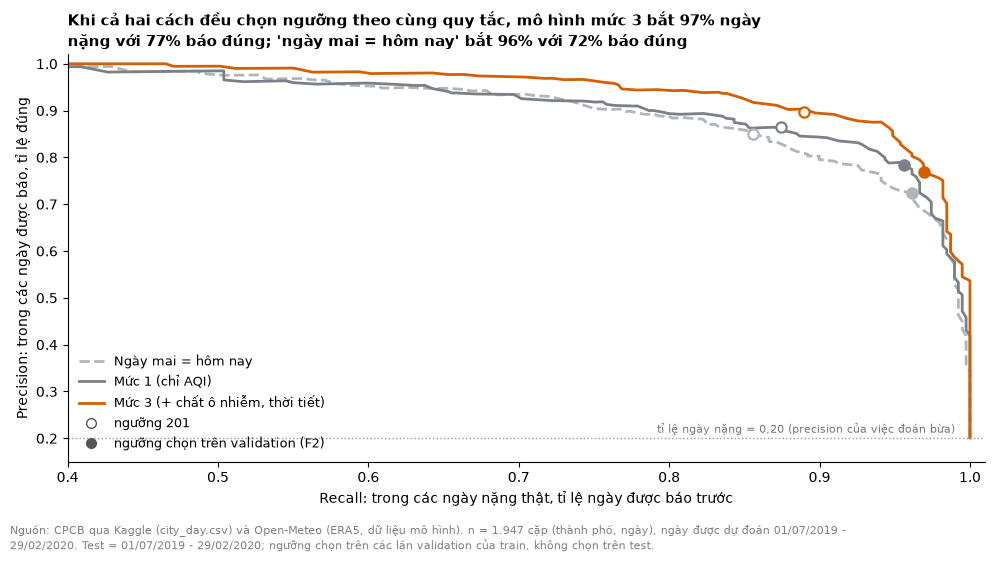

In [17]:
grid = np.arange(40, 401, 2)
def pr_curve(score):
    pts = [alert_metrics(y_te, score >= t) for t in grid]
    return np.array([[p["recall"], p["precision"]] for p in pts if p["n_canh_bao"] > 0])
curves = {PERSIST: (aq_te, thr_p, NEUTRAL, "--"), "Ridge L1": (pred_te["Ridge L1"], thr["L1"], "#7A8087", "-"), "Ridge L3": (pred_te["Ridge L3"], thr["L3"], ACCENT, "-")}
nm = {PERSIST: "Ngày mai = hôm nay", "Ridge L1": "Mức 1 (chỉ AQI)", "Ridge L3": "Mức 3 (+ chất ô nhiễm, thời tiết)"}
fig, ax = plt.subplots(figsize=(10, 5.6))
for k, (sc, t_star, col, ls) in curves.items():
    c = pr_curve(sc); ax.plot(c[:, 0], c[:, 1], color=col, ls=ls, lw=2, label=nm[k])
    for t_, filled in [(201, False), (t_star, True)]:
        mm = alert_metrics(y_te, sc >= t_)
        ax.scatter(mm["recall"], mm["precision"], s=55, facecolor=col if filled else "white", edgecolor=col, zorder=4, lw=1.6)
ax.axhline(y_te.mean(), color="#999999", lw=1, ls=":"); ax.text(0.99, y_te.mean() + 0.012, f"tỉ lệ ngày nặng = {vn(y_te.mean(), 2)} (precision của việc đoán bừa)", fontsize=8, color="#777777", ha="right")
ax.set_xlabel("Recall: trong các ngày nặng thật, tỉ lệ ngày được báo trước"); ax.set_ylabel("Precision: trong các ngày được báo, tỉ lệ đúng")
from matplotlib.lines import Line2D
ax.set_xlim(0.4, 1.01); ax.set_ylim(0.15, 1.02)
h, l = ax.get_legend_handles_labels()
h += [Line2D([], [], marker="o", ls="", mfc="white", mec="#555555", ms=7), Line2D([], [], marker="o", ls="", mfc="#555555", mec="#555555", ms=7)]
l += ["ngưỡng 201", "ngưỡng chọn trên validation (F2)"]
ax.legend(h, l, frameon=False, loc="lower left", fontsize=9)
r3, r_p = alert_metrics(y_te, flags[K["L3t"]]), alert_metrics(y_te, flags[K["pt"]])
assert r3["precision"] > r_p["precision"] and abs(r3["recall"] - r_p["recall"]) < 0.03, "Quan hệ recall/precision đã đổi: sửa tiêu đề"
finish_chart(fig, ax, f"Khi cả hai cách đều chọn ngưỡng theo cùng quy tắc, mô hình mức 3 bắt {vn(r3['recall'] * 100)}% ngày nặng với {vn(r3['precision'] * 100)}% báo đúng; "
                      f"'ngày mai = hôm nay' bắt {vn(r_p['recall'] * 100)}% với {vn(r_p['precision'] * 100)}% báo đúng", te,
             note="Test = 01/07/2019 - 29/02/2020; ngưỡng chọn trên các lần validation của train, không chọn trên test.")
save_fig(fig, "04_precision_recall")


### Đọc biểu đồ 4

- Đường của mức 3 (cam) **nằm trên** đường của "ngày mai = hôm nay" (xám nhạt) ở hầu hết khoảng recall từ 0,6 đến 0,95: ở cùng recall, báo đúng nhiều hơn. Hai đường chụm lại ở recall rất cao (trên 0,97), vì bắt gần hết ngày nặng thì mọi cách đều phải chấp nhận nhiều báo nhầm.
- Vòng tròn rỗng (ngưỡng 201) và chấm đặc (ngưỡng chọn bằng F2) cho thấy **cùng một mô hình có thể vận hành ở nhiều điểm**. Chọn điểm nào là quyết định của cơ quan môi trường (cảnh báo thừa tốn bao nhiêu so với bỏ sót), không phải của mô hình.
- Đường nằm xa đường ngang "đoán bừa" (precision 0,20): mọi cách đều học được điều gì đó thật, nhưng phần lớn đã có trong baseline.

## Theo nhóm thành phố

In [18]:
groups = {"Delhi, Gurugram, Lucknow": ["Delhi", "Gurugram", "Lucknow"], "Jaipur, Amritsar": ["Jaipur", "Amritsar"], "Bengaluru, Chennai, Hyderabad": ["Bengaluru", "Chennai", "Hyderabad"]}
rows = []
for g_, cs in groups.items():
    mk = te.City.isin(cs).to_numpy()
    r = {"nhóm": g_, "n": int(mk.sum()), "ngày nặng": int(y_te[mk].sum())}
    for lab, fl in [("hôm nay@201", flags[K["p201"]]), ("hôm nay@ngưỡng", flags[K["pt"]]), ("mức 3@ngưỡng", flags[K["L3t"]])]:
        m = alert_metrics(y_te[mk], fl[mk])
        enough = r["ngày nặng"] >= 30                           # quy ước W12 của nhóm: dưới 30 ngày nặng thì không báo tỉ lệ
        r[f"recall {lab}"] = m["recall"] if enough else np.nan
        r[f"precision {lab}"] = m["precision"] if enough else np.nan
    rows.append(r)
group_tab = pd.DataFrame(rows).set_index("nhóm")
display(group_tab.round(2))
print("NaN = nhóm có dưới 30 ngày nặng trong tập test: không đủ để báo recall/precision.")

,n,ngày nặng,recall hôm nay@201,precision hôm nay@201,recall hôm nay@ngưỡng,precision hôm nay@ngưỡng,recall mức 3@ngưỡng,precision mức 3@ngưỡng
nhóm,,,,,,,,
"Delhi, Gurugram, Lucknow",732,341,0.89,0.88,0.98,0.80,0.99,0.82
"Jaipur, Amritsar",483,38,0.63,0.63,0.89,0.45,0.84,0.49
"Bengaluru, Chennai, Hyderabad",732,10,NaN,NaN,NaN,NaN,NaN,NaN


NaN = nhóm có dưới 30 ngày nặng trong tập test: không đủ để báo recall/precision.


### Đọc bảng theo nhóm thành phố (W12: báo kết quả theo nhóm, không chỉ tổng thể)

- **Delhi, Gurugram, Lucknow (341 ngày nặng):** recall 0,99 và precision 0,82 ở ngưỡng chọn, tốt hơn tổng thể. Phần lớn điểm của bảng tổng nằm ở ba thành phố này.
- **Jaipur và Amritsar (chỉ 38 ngày nặng trong test):** recall 0,84 (**thấp hơn** "hôm nay" ở cùng ngưỡng là 0,89) và precision 0,49. Cảnh báo ở hai thành phố này kém tin cậy hơn nhiều, và mẫu nhỏ nên con số cũng chưa chắc. **Không nên nói "mô hình dùng được cho cả 8 thành phố".**
- **Bengaluru, Chennai, Hyderabad (10 ngày nặng):** không đủ để đánh giá cảnh báo (dưới 30 ngày nặng), nên không có số. Đây là một **giới hạn phải ghi vào model card**: mô hình cảnh báo chưa được kiểm chứng ở miền Nam, nơi hầu như không có ngày nặng.

# Phần G — Kiểm lại độ ẩm và nhiệt độ (phát hiện khám phá của notebook 05)

Notebook 05 chọn độ ẩm **sau khi nhìn kết quả**, nên cần kiểm lại. Cần nói rõ một điều: 05 phân tích toàn bộ khoảng chung 06/2017 – 07/2020, tức **đã gồm cả giai đoạn test**. Vì vậy giai đoạn test **không phải tập "chưa từng thấy" cho riêng phát hiện đó**. Cách làm trung thực hơn là chạy **đúng cách làm của 05** (lệch so với ngày điển hình cùng thành phố, cùng tháng; tertile trong từng tháng) trên **hai giai đoạn tách rời**, train và test, rồi xem hai giai đoạn có cùng chiều không. Kiểm chứng thật sự "ngoài mẫu" là ở Phần D và E: hệ số độ ẩm ở Phần D chỉ fit trên train (âm, loại trừ 0), và Phần E cho thấy thêm thời tiết giảm sai số trên test.

In [19]:
from corr_utils import add_anomalies, tertile_in_strata
eda_w, win_w, S0, E0 = load_with_weather(verbose=False)
dw = win_w.dropna(subset=["AQI"]).copy()
core, n_heavy_all = core_cities(dw)                                   # 5 thành phố đủ ngày nặng (quy ước C1 của notebook 03)
periods = {"train (06/2017-06/2019)": dw[dw.Date <= TRAIN_END], "test (07/2019-02/2020)": dw[(dw.Date >= TEST_START) & (dw.Date <= TEST_END)]}

def replicate(d):
    # đúng cách làm của notebook 05 trên MỘT giai đoạn: lệch so với ngày điển hình cùng thành phố, cùng tháng; tertile độ ẩm trong từng (thành phố, tháng)
    a = add_anomalies(d, ["AQI", "humidity_mean", "temp_mean"])
    rows = []
    for c in core:
        g = a[a.City == c].copy()
        g["blk"] = block_id(g).to_numpy(); g["t"] = tertile_in_strata(g, "humidity_mean").to_numpy()
        rh = boot_corr(g.AQI_a, g.humidity_mean_a, g.blk); rt = boot_corr(g.AQI_a, g.temp_mean_a, g.blk)
        lo_, hi_, pz = (g.t == "thấp").to_numpy(), (g.t == "cao").to_numpy(), g.poor.to_numpy()
        d_, dlo, dhi = block_boot(g.blk.to_numpy(), np.column_stack([pz & lo_, lo_, pz & hi_, hi_]), lambda s: (s[:, 0] / s[:, 1] - s[:, 2] / s[:, 3]) * 100)
        rows.append({"Thành phố": c, "n ngày": len(g), "ngày nặng": int(pz.sum()),
                     "ρ độ ẩm": rh["rho"], "ρ độ ẩm KTC": f"[{rh['lo']:.2f}; {rh['hi']:.2f}]", "ρ nhiệt độ": rt["rho"], "ρ nhiệt độ KTC": f"[{rt['lo']:.2f}; {rt['hi']:.2f}]",
                     "% nặng, ẩm thấp": g[lo_].poor.mean() * 100, "% nặng, ẩm cao": g[hi_].poor.mean() * 100, "chênh (điểm %)": d_, "chênh KTC": f"[{dlo:.0f}; {dhi:.0f}]"})
    return pd.DataFrame(rows).set_index("Thành phố")
recheck = {k: replicate(v) for k, v in periods.items()}
for k, v in recheck.items():
    print(k); display(v.round(2))

train (06/2017-06/2019)


,n ngày,ngày nặng,ρ độ ẩm,ρ độ ẩm KTC,ρ nhiệt độ,ρ nhiệt độ KTC,"% nặng, ẩm thấp","% nặng, ẩm cao",chênh (điểm %),chênh KTC
Thành phố,,,,,,,,,,
Delhi,738,423,-0.20,[-0.34; -0.07],0.18,[0.04; 0.32],67.07,48.79,18.28,[3; 33]
Gurugram,703,396,-0.15,[-0.26; -0.03],0.14,[0.02; 0.26],63.18,49.57,13.61,[-0; 27]
Lucknow,744,398,-0.10,[-0.21; 0.02],0.09,[-0.06; 0.24],55.38,48.21,7.17,[-8; 23]
Jaipur,726,112,-0.39,[-0.49; -0.29],0.28,[0.17; 0.39],22.36,9.43,12.93,[3; 24]
Amritsar,672,87,-0.17,[-0.30; -0.04],0.23,[0.12; 0.34],13.04,13.45,-0.41,[-12; 12]


test (07/2019-02/2020)


,n ngày,ngày nặng,ρ độ ẩm,ρ độ ẩm KTC,ρ nhiệt độ,ρ nhiệt độ KTC,"% nặng, ẩm thấp","% nặng, ẩm cao",chênh (điểm %),chênh KTC
Thành phố,,,,,,,,,,
Delhi,244,133,-0.28,[-0.44; -0.10],0.11,[-0.06; 0.31],62.35,43.75,18.60,[-6; 41]
Gurugram,244,97,-0.32,[-0.47; -0.15],0.17,[-0.01; 0.36],45.88,30.00,15.88,[-9; 38]
Lucknow,244,111,-0.15,[-0.31; 0.02],-0.01,[-0.16; 0.14],50.59,40.00,10.59,[-17; 35]
Jaipur,244,9,-0.30,[-0.48; -0.10],0.24,[0.04; 0.43],3.53,3.75,-0.22,[-5; 3]
Amritsar,241,29,-0.20,[-0.34; -0.02],0.13,[-0.01; 0.27],14.46,10.13,4.33,[-3; 11]


## Biểu đồ 5: tỉ lệ ngày AQI ≥ 201 theo nhóm độ ẩm, hai giai đoạn

Đã lưu reports\figures\model_05_humidity_recheck.png


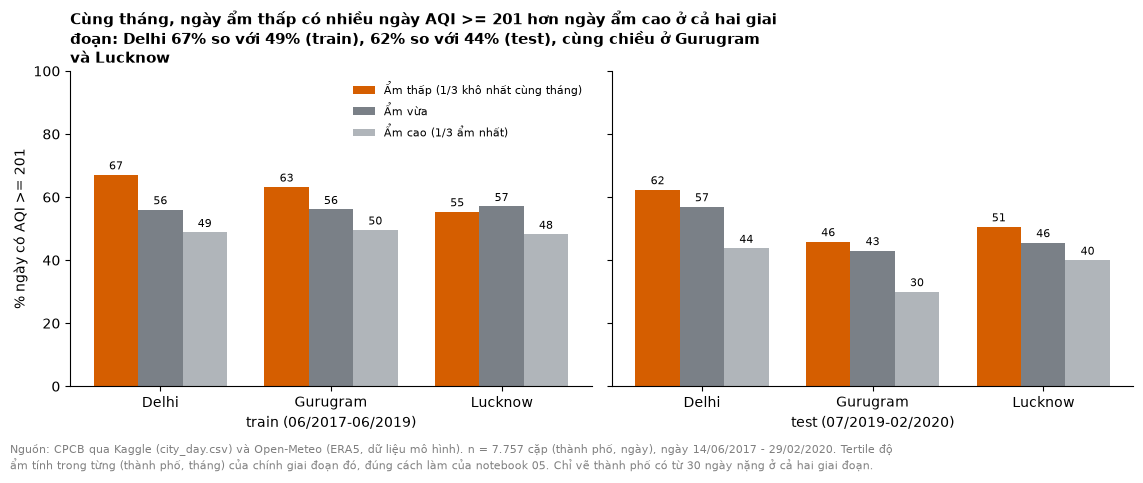

In [20]:
three = [c for c in core if all(recheck[k].loc[c, "ngày nặng"] >= 30 for k in recheck)]       # đủ 30 ngày nặng ở CẢ hai giai đoạn
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), sharey=True)
for ax, (k, d_) in zip(axes, periods.items()):
    a_ = add_anomalies(d_, ["humidity_mean"]); xs = np.arange(len(three)); w_ = 0.26
    for q, (g_, cc_, nm_) in enumerate(zip(["thấp", "giữa", "cao"], [ACCENT, "#7A8087", NEUTRAL], ["Ẩm thấp (1/3 khô nhất cùng tháng)", "Ẩm vừa", "Ẩm cao (1/3 ẩm nhất)"])):
        vals_ = []
        for c in three:
            g = a_[a_.City == c]; vals_.append(g[tertile_in_strata(g, "humidity_mean") == g_].poor.mean() * 100)
        b = ax.bar(xs + (q - 1) * w_, vals_, w_, color=cc_, label=nm_); ax.bar_label(b, labels=[vn(v) for v in vals_], padding=2, fontsize=8)
    ax.set_xticks(xs); ax.set_xticklabels(three); ax.set_ylim(0, 100); ax.set_xlabel(k)
axes[0].set_ylabel("% ngày có AQI >= 201"); axes[0].legend(frameon=False, ncol=1, fontsize=8, loc="upper right")
tr_k, te_k = list(recheck)
d_tr, d_te = recheck[tr_k].loc["Delhi"], recheck[te_k].loc["Delhi"]
assert all(recheck[k].loc[c, "chênh (điểm %)"] > 0 for k in recheck for c in three), "Chiều đã đổi: sửa tiêu đề"
finish_chart(fig, axes[0], f"Cùng tháng, ngày ẩm thấp có nhiều ngày AQI >= 201 hơn ngày ẩm cao ở cả hai giai đoạn: Delhi {vn(d_tr['% nặng, ẩm thấp'])}% so với {vn(d_tr['% nặng, ẩm cao'])}% (train), "
                         f"{vn(d_te['% nặng, ẩm thấp'])}% so với {vn(d_te['% nặng, ẩm cao'])}% (test), cùng chiều ở Gurugram và Lucknow", pd.concat(periods.values()),
             note="Tertile độ ẩm tính trong từng (thành phố, tháng) của chính giai đoạn đó, đúng cách làm của notebook 05. Chỉ vẽ thành phố có từ 30 ngày nặng ở cả hai giai đoạn.")
save_fig(fig, "05_humidity_recheck")


### Đọc bảng và biểu đồ 5

- **Độ ẩm: chiều âm lặp lại ở cả hai giai đoạn và cả 5 thành phố** (ρ từ −0,10 đến −0,39 ở train, từ −0,15 đến −0,32 ở test). Khoảng tin cậy loại trừ 0 ở 8/10 trường hợp; hai trường hợp còn lại là Lucknow (ρ −0,10 và −0,15, khoảng tin cậy chứa 0).
- **Nhiệt độ: chiều dương lặp lại ở 9/10 trường hợp** (ngoại lệ Lucknow ở test, ρ −0,01). Như ở 05, chỉ nên nói về chiều, không nói về độ lớn.
- **Tỉ lệ ngày nặng ở nhóm ẩm thấp cao hơn nhóm ẩm cao ở Delhi, Gurugram và Lucknow, ở cả hai giai đoạn** (Delhi +18 điểm % ở cả train lẫn test). Nhưng **khoảng tin cậy của chênh lệch chứa 0 ở 5/6 trường hợp** (chỉ Delhi ở train tách khỏi 0): **chiều nhất quán, độ lớn chưa chắc**. Con số "64% so với 38%" ở notebook 05 là tổng hợp cả khoảng chung và không nên trích như ước lượng độ lớn đáng tin; nên nói "cao hơn một chút đến khá nhiều tuỳ thành phố".
- Giống 05: độ ẩm cao có thể đại diện cho mưa, sương mù, mây hoặc một khối khí khác. Kết quả vẫn là **"đi cùng"**, không phải "gây ra".

# Phần H — Giai đoạn phong toả 03–07/2020 (tách riêng, không dùng để chọn gì)

Mô hình fit trên train (trước phong toả) rồi dự đoán 975 cặp (thành phố, ngày) từ 01/03 đến 01/07/2020. Mục đích: xem mô hình có lệch hệ thống khi nguồn phát thải đổi đột ngột không. Chỉ 18 ngày nặng nên **không tính recall và precision**.

In [21]:
heavy_lk = lk.y_poor.to_numpy()
lock_tab = pd.DataFrame({k: {"MAE": mae(lk.y, pred_lk[k]), "RMSE": rmse(lk.y, pred_lk[k]), "AQI dự đoán TB": pred_lk[k].mean()}
                         for k in [PERSIST, "Ridge L1", "Ridge L2", "Ridge L3", "Ridge L4"]}).T
lock_tab.loc["Thực tế", ["AQI dự đoán TB"]] = lk.y.mean()
display(lock_tab.round(1))
print(f"{len(lk)} cặp (thành phố, ngày) từ {lk.Date_target.min():%d/%m/%Y} đến {lk.Date_target.max():%d/%m/%Y}; chỉ {int(heavy_lk.sum())} ngày AQI >= 201 ({heavy_lk.mean()*100:.1f}%) nên KHÔNG tính recall/precision.")
print(f"Tập test cùng chỉ số (để so): MAE hôm nay {test_tab.loc[PERSIST,'MAE']:.1f}, mức 3 {test_tab.loc['Ridge L3','MAE']:.1f}; AQI thực tế TB {te.y.mean():.1f}")

,MAE,RMSE,AQI dự đoán TB
Ngày mai = hôm nay,14.8,26.9,96.8
Ridge L1,14.1,24.3,98.8
Ridge L2,13.9,23.0,98.0
Ridge L3,13.8,22.6,98.7
Ridge L4,13.7,22.4,99.2
Thực tế,NaN,NaN,96.6


975 cặp (thành phố, ngày) từ 01/03/2020 đến 01/07/2020; chỉ 18 ngày AQI >= 201 (1.8%) nên KHÔNG tính recall/precision.
Tập test cùng chỉ số (để so): MAE hôm nay 23.5, mức 3 19.5; AQI thực tế TB 139.0


### Đọc bảng

- Sai số **thấp hơn hẳn** giai đoạn test (MAE 13,8 so với 19,5 của mức 3) vì AQI trong phong toả thấp và ổn định (trung bình ~97 so với 139 ở test). Đừng đọc là "mô hình tốt hơn".
- Mức 3 vẫn hơn "hôm nay" (13,8 so với 14,8), cùng chiều với test nhưng chênh nhỏ.
- **Không có dấu hiệu lệch hệ thống**: AQI dự đoán trung bình 98,7 so với thực tế 96,6. Mô hình không "hoảng" vì phát thải giảm đột ngột, một phần vì lịch sử AQI hôm nay đã cập nhật mức nền mới.

# Phần I — Kiểm tra độ nhạy (cho câu vấn đáp "nếu đổi cách làm, kết luận có đổi không?")

Năm kiểm tra, đều đo **hiệu số MAE** vì đó là phát hiện chính (mức 3 so với mức 1 và so với "hôm nay"):
1. **Bỏ ngẫu nhiên 10% dòng train**, lặp 100 lần (câu vấn đáp W8).
2. **Bỏ Gurugram** (thời tiết gần trùng Delhi, không phải bằng chứng độc lập).
3. **Giữ lại các ô nội suy** thay vì đặt lại NaN (kiểm tra quyết định thiết kế 3).
4. **Tách test thành hai giai đoạn**: 07–11/2019 (mưa và sau mưa) và 12/2019–02/2020 (mùa đông).
5. **Bỏ hai biến mùa** (sin, cos): thời tiết còn giúp không nếu không có mùa đi kèm.

In [22]:
fit_mae = lambda d_tr, d_te, lv: mae(d_te.y, np.exp(make_pipe(LEVELS[lv], "ridge", alpha=best_alpha[lv]).fit(d_tr[LEVELS[lv] + ["City"]], d_tr.y_log).predict(d_te[LEVELS[lv] + ["City"]])))
rng = np.random.default_rng(42)
drops = []
for _ in range(100):
    s = tr.sample(frac=0.9, random_state=int(rng.integers(1e9))).sort_index()
    a1, a3 = fit_mae(s, te, "L1"), fit_mae(s, te, "L3")
    drops.append((a3 - a1, a3 - mae(te.y, te.AQI)))
drops = np.array(drops)
print("Bỏ ngẫu nhiên 10% dòng train, 100 lần (câu vấn đáp W8):")
display(pd.DataFrame({"ΔMAE mức 3 trừ mức 1": [drops[:, 0].min(), np.median(drops[:, 0]), drops[:, 0].max()],
                      "ΔMAE mức 3 trừ 'hôm nay'": [drops[:, 1].min(), np.median(drops[:, 1]), drops[:, 1].max()]}, index=["nhỏ nhất", "trung vị", "lớn nhất"]).round(2))

Bỏ ngẫu nhiên 10% dòng train, 100 lần (câu vấn đáp W8):


,ΔMAE mức 3 trừ mức 1,ΔMAE mức 3 trừ 'hôm nay'
nhỏ nhất,-3.52,-4.02
trung vị,-3.41,-3.93
lớn nhất,-3.30,-3.81


In [23]:
ng = ds[ds.City != "Gurugram"]
trg, teg = ng[ng.split == "train"], ng[ng.split == "test"]
blg = calendar_blocks(teg.Date_target)
e_p, e1, e3 = (np.abs(teg.y.to_numpy() - teg.AQI.to_numpy()),
               *[np.abs(teg.y.to_numpy() - np.exp(make_pipe(LEVELS[lv], "ridge", alpha=best_alpha[lv]).fit(trg[LEVELS[lv] + ["City"]], trg.y_log).predict(teg[LEVELS[lv] + ["City"]]))) for lv in ["L1", "L3"]])
r1, r2_ = boot_mae_diff(blg, e3, e_p), boot_mae_diff(blg, e3, e1)
print(f"Bỏ Gurugram (thời tiết gần trùng Delhi): MAE hôm nay {e_p.mean():.2f}, mức 1 {e1.mean():.2f}, mức 3 {e3.mean():.2f}")
print(f"  mức 3 − hôm nay: {r1[0]:+.2f} (KTC 95% {r1[1]:+.2f} đến {r1[2]:+.2f}) · mức 3 − mức 1: {r2_[0]:+.2f} ({r2_[1]:+.2f} đến {r2_[2]:+.2f})")

Bỏ Gurugram (thời tiết gần trùng Delhi): MAE hôm nay 21.51, mức 1 20.98, mức 3 18.16
  mức 3 − hôm nay: -3.36 (KTC 95% -4.63 đến -2.11) · mức 3 − mức 1: -2.83 (-3.93 đến -1.77)


In [24]:
ds_nm = build_dataset(mask_interp=False, verbose=False)               # giữ nguyên các ô đã nội suy ở bước làm sạch
tr_nm, te_nm = ds_nm[ds_nm.split == "train"], ds_nm[ds_nm.split == "test"]
assert len(tr_nm) == len(tr) and len(te_nm) == len(te)
chg = (np.abs(ds_nm[POLL_FEATS].to_numpy() - ds[POLL_FEATS].to_numpy()) > 1e-9) & ds_nm[POLL_FEATS].notna().to_numpy()
rows = []
for lv in ["L2", "L3"]:
    rows.append({"mức": lv, "MAE (đặt lại NaN, dùng trong notebook)": fit_mae(tr, te, lv), "MAE (giữ ô nội suy)": fit_mae(tr_nm, te_nm, lv)})
mi = pd.DataFrame(rows).set_index("mức"); mi["chênh"] = mi.iloc[:, 1] - mi.iloc[:, 0]
display(mi.round(2))
print(f"{chg.any(axis=1).mean()*100:.1f}% số dòng có ít nhất một chất ô nhiễm bị đổi giá trị bởi bước đặt lại NaN.")

,"MAE (đặt lại NaN, dùng trong notebook)",MAE (giữ ô nội suy),chênh
mức,,,
L2,20.92,20.92,0.01
L3,19.52,19.55,0.03


1.1% số dòng có ít nhất một chất ô nhiễm bị đổi giá trị bởi bước đặt lại NaN.


In [25]:
mo = te.Date_target.dt.month
per = {"07-11/2019 (mưa, sau mưa)": (mo >= 7) & (mo <= 11), "12/2019-02/2020 (mùa đông)": (mo == 12) | (mo <= 2)}
rows = []
for name, mk in per.items():
    mk = mk.to_numpy()
    rows.append({"giai đoạn test": name, "n": int(mk.sum()), "ngày nặng": int(y_te[mk].sum()), "MAE hôm nay": mae(te.y[mk], pred_te[PERSIST][mk]),
                 "MAE mức 1": mae(te.y[mk], pred_te["Ridge L1"][mk]), "MAE mức 3": mae(te.y[mk], pred_te["Ridge L3"][mk])})
subp = pd.DataFrame(rows).set_index("giai đoạn test"); display(subp.round(2))

,n,ngày nặng,MAE hôm nay,MAE mức 1,MAE mức 3
giai đoạn test,,,,,
"07-11/2019 (mưa, sau mưa)",1222,178,20.67,20.47,17.98
12/2019-02/2020 (mùa đông),725,211,28.17,27.10,22.12


In [26]:
no_cal = lambda lv: [x for x in LEVELS[lv] if x not in CAL_FEATS]
def fit_nc(lv):
    f = no_cal(lv)
    return mae(te.y, np.exp(make_pipe(f, "ridge", alpha=best_alpha[lv]).fit(tr[f + ["City"]], tr.y_log).predict(te[f + ["City"]])))
nc1, nc3 = fit_nc("L1"), fit_nc("L3")
print(f"Bỏ hai biến mùa (sin, cos): MAE mức 1 {nc1:.2f}, mức 3 {nc3:.2f}, chênh {nc3 - nc1:+.2f}  (có biến mùa: {test_tab.loc['Ridge L1','MAE']:.2f}, {test_tab.loc['Ridge L3','MAE']:.2f}, chênh {test_tab.loc['Ridge L3','MAE'] - test_tab.loc['Ridge L1','MAE']:+.2f})")

Bỏ hai biến mùa (sin, cos): MAE mức 1 23.14, mức 3 19.60, chênh -3.53  (có biến mùa: 22.94, 19.52, chênh -3.42)


### Đọc kết quả độ nhạy

- **Bỏ 10% dòng train:** hiệu số mức 3 − mức 1 chỉ dao động từ −3,52 đến −3,30 qua 100 lần, và mức 3 − "hôm nay" từ −4,02 đến −3,81. Kết luận không phụ thuộc vào vài dòng cụ thể. (Biên độ nhỏ vì đây là xáo trộn của train, không phải của test; độ không chắc của test nằm ở khoảng tin cậy bootstrap theo khối ở Phần E.)
- **Bỏ Gurugram:** mức 3 vẫn hơn "hôm nay" 3,36 điểm (−4,63 đến −2,11) và hơn mức 1 là 2,83 điểm (−3,93 đến −1,77). Kết quả **không do việc đếm Delhi và Gurugram hai lần**.
- **Giữ ô nội suy:** MAE đổi 0,01 (mức 2) và 0,03 (mức 3), trong khi chỉ 1,1% số dòng có chất bị đổi. Rò rỉ nhẹ này **không làm đẹp kết quả**; việc đặt lại NaN là đúng nguyên tắc và không tốn gì.
- **Hai giai đoạn của test:** lợi thế của mức 3 có ở cả hai, nhưng **lớn hơn ở mùa đông** (MAE 28,2 → 22,1, giảm 21%) so với mưa và sau mưa (20,7 → 18,0, giảm 13%). Nghĩa là phần lớn giá trị nằm ở mùa đông, đúng lúc khó và cần cảnh báo nhất.
- **Bỏ biến mùa:** hiệu số mức 3 − mức 1 gần như không đổi (−3,53 so với −3,42). Thời tiết **không chỉ đóng vai trò thay mùa**.

# Tổng hợp

## Trả lời câu hỏi nghiên cứu (phần dự đoán và cảnh báo)

**Có, nhưng khiêm tốn, và phần đóng góp riêng của thời tiết nhỏ hơn phần của chất ô nhiễm.**

- Dự đoán AQI ngày mai: mô hình có thời tiết giảm sai số **16,8%** so với "ngày mai = hôm nay" (23,5 → 19,5 điểm). Riêng thời tiết giảm thêm khoảng **1,4 điểm** (~7%) sau khi đã có AQI và chất ô nhiễm.
- Cảnh báo ngày AQI ≥ 201: ở cùng ngưỡng 201, mô hình hơn baseline ở cả recall, precision và F1. Ở ngưỡng chọn công bằng, mô hình **báo đúng hơn ~4,6 điểm %** với cùng recall. **Phần riêng của thời tiết không tách khỏi 0** ở bài toán cảnh báo.

## Phát hiện (mỗi ý gắn một biểu đồ hoặc bảng)

| # | Phát hiện (có con số) | Hình / bảng | Confounder có thể | Hạn chế |
|---|---|---|---|---|
| P1 | "Ngày mai = hôm nay" sai 23,5 điểm AQI trên test (R² 0,86), so với 64,5 (trung bình thành phố) và 43,4 (khí hậu cùng tháng). Mô hình chỉ có lịch sử AQI (22,9) chưa tách khỏi baseline (−0,5; −1,2 đến +0,1). | 2 | Quán tính của chính chuỗi AQI | Baseline mạnh nên mọi chênh lệch đều nhỏ về tuyệt đối |
| P2 | Hai bậc thang đều tách khỏi 0: + chất ô nhiễm −2,0; + thời tiết −1,4 (−1,9 đến −0,9); tổng so với "hôm nay" −3,95 (−5,4 đến −2,6), giảm 16,8%. Biết trước thời tiết ngày mai chỉ thêm −0,4. | 2, bảng E | Mùa (đã có biến mùa; bỏ biến mùa không đổi kết luận) | Một mùa đông test; thời tiết là tái phân tích ERA5, không phải số đo tại trạm |
| P3 | Mức giảm sai số cùng chiều ở cả 8 thành phố, lớn nhất ở Delhi (36,7 → 29,3), Lucknow (29,1 → 22,7), Gurugram (37,1 → 30,1). Trên ngày nặng: 47,5 → 39,8. | 3 | Delhi và Gurugram không độc lập (đã kiểm tra bằng cách bỏ Gurugram) | Sai số tuyệt đối miền Nam nhỏ vì AQI thấp, không so trực tiếp giữa thành phố |
| P4 | Hệ số thời tiết (train, sai số chuẩn bền): độ ẩm −1,2% mỗi 10 điểm %, gió −1,9% mỗi m/s, mưa 10 mm −9,2%. Nhiệt độ, lớp biên, áp suất không tách khỏi 0. | Bảng D | Hệ số có điều kiện theo AQI và chất ô nhiễm hôm nay; VIF nhiệt độ 8,8 | "Đi cùng với", không phải nguyên nhân; hệ số AQI trễ không diễn giải riêng lẻ (VIF đến 14,5) |
| P5 | Cảnh báo ở ngưỡng 201: mức 3 recall 0,89, precision 0,90 so với 0,86 và 0,85 của "hôm nay" (F1 +0,040; 0,027 đến 0,055). Ngưỡng chọn công bằng: precision +0,046 (0,024 đến 0,074), recall chưa khác (+0,008). Mức 3 so với mức 2: cả ba chỉ số chứa 0. | 4, bảng F | Mức nền ô nhiễm giảm theo thời gian (25% → 20% ngày nặng) | Ngưỡng chọn bằng F2 là một nhận định chi phí; chỉ một mùa đông |
| P6 | Theo nhóm: Delhi, Gurugram, Lucknow (341 ngày nặng) recall 0,99, precision 0,82. Jaipur và Amritsar (38 ngày nặng) recall 0,84, precision 0,49, **kém hơn**. Miền Nam (10 ngày nặng): không đủ để đánh giá. | Bảng F (nhóm) | Nguồn phát thải khác nhau theo vùng (bụi, đốt rơm rạ) | Không nên nói mô hình dùng được cho cả 8 thành phố |
| P7 | Độ ẩm: ρ âm ở cả 5 thành phố và cả hai giai đoạn (8/10 loại trừ 0); nhiệt độ ρ dương 9/10. Chênh tỉ lệ ngày nặng (ẩm thấp − ẩm cao) dương ở Delhi, Gurugram, Lucknow ở cả hai giai đoạn nhưng khoảng tin cậy chứa 0 ở 5/6. | 5, bảng G | Mưa, sương mù, mây (độ ẩm là đại diện) | 05 đã dùng cả giai đoạn test nên đây không phải kiểm chứng độc lập; chiều chắc, độ lớn chưa |
| P8 | Phong toả: MAE 14,8 ("hôm nay") và 13,8 (mức 3); AQI dự đoán trung bình 98,7 so với thực 96,6: không lệch hệ thống. | Bảng H | Phát thải đổi đột ngột | Chỉ 18 ngày nặng: không đánh giá cảnh báo |
| P9 | Cây tăng cường mức 3 tốt hơn Ridge mức 3 trên test (18,0 so với 19,5; −1,5; −2,2 đến −0,7) dù hoà trên validation. | Bảng E | Phi tuyến; đặc điểm riêng của test | Không đổi mô hình chính sau khi thấy test; báo cả hai |

## Hạn chế (cụ thể, gắn với kết luận nó đe doạ)

- **Chỉ một mùa đông trong test (07/2019 – 02/2020).** Khoảng tin cậy bootstrap theo khối cho biết sai số lấy mẫu trong mùa đó, nhưng **không** cho biết mô hình sẽ ra sao ở mùa đông 2020–21 (khác về thời tiết và phát thải). Đe doạ P2, P5.
- **Train chỉ có hai mùa đông** (2017–18 và 2018–19), nên cả việc học lẫn việc chọn ngưỡng dựa trên hai mùa. Đe doạ P5.
- **Tỉ lệ ngày nặng giảm theo thời gian** (24,9% train → 20,0% test → 1,8% phong toả). Ngưỡng chọn trên train có thể hơi lệch cho giai đoạn sau. Đe doạ P5.
- **Thời tiết là tái phân tích ERA5 trên ô lưới 0,25°, không phải số đo tại trạm quan trắc.** Dùng thời tiết thực tế đến hôm nay không phải là dự báo; khi triển khai thật phải thay bằng dự báo của ngày mai, mà kịch bản "cận trên" cho thấy lợi ích thêm vào chỉ khoảng 0,4 điểm. Đe doạ P2.
- **Ngày thiếu AQI (5,9%) bị loại**, nên không dự đoán được cho những ngày đó. Nếu thiếu AQI tập trung vào ngày nặng (cảm biến quá tải) thì mô hình trông tốt hơn thực tế. Chưa kiểm tra được.
- **Miền Nam không có ngày nặng**, nên cảnh báo chưa được kiểm chứng ở đó; **Jaipur và Amritsar** chỉ có 38 ngày nặng. Đe doạ P6.
- **Mô hình hụt ở các đợt tăng đột ngột** (đuôi phải nặng ở QQ-plot). Với bài toán cảnh báo sức khỏe, đây là đúng loại sai sót đắt nhất.
- **Chỉ số AQI là chỉ số tổng hợp theo ngày của CPCB** (theo thang Ấn Độ), nên kết quả không chuyển nguyên sang thang AQI của nước khác.

## Biến thể để các bạn trong nhóm thử (tránh bốn phiên bản khác nhau: giữ nguyên `model_utils.py`, chỉ thử trong notebook riêng)

1. Thêm biến trễ của thời tiết (hôm qua, hai ngày trước) hoặc trung bình trượt 3 ngày, và xem phần riêng của thời tiết ở bài toán cảnh báo có tách khỏi 0 không.
2. Mô hình riêng cho nhóm Delhi–Gurugram–Lucknow (hỗn hợp một mô hình cho 8 thành phố có thể đang làm Jaipur và Amritsar kém đi).
3. Đổi tiêu chí chọn ngưỡng (F1, hoặc recall cố định 0,95 rồi tối đa precision) và xem hình 4 đổi ra sao.
4. Giữ Ridge nhưng thêm vài tương tác thành phố × độ ẩm hoặc thành phố × gió, rồi so với cây tăng cường.

## Kiểm tra lại các con số trong bảng phát hiện

In [27]:
close = lambda x, v, tol=0.05: abs(float(x) - v) <= tol
T = test_tab["MAE"]
assert all(close(T[k], v) for k, v in [(PERSIST, 23.47), ("Ridge L1", 22.94), ("Ridge L2", 20.92), ("Ridge L3", 19.52), ("Ridge L4", 19.08), ("Trung bình theo thành phố", 64.47), ("Trung vị cùng tháng (khí hậu)", 43.41)])
assert close(test_tab.loc[PERSIST, "R²"], 0.86, 0.006) and close(test_tab.loc["Ridge L3", "R²"], 0.91, 0.006)
assert close(test_tab.loc[PERSIST, "RMSE"], 37.61, 0.1) and close(test_tab.loc["Ridge L3", "RMSE"], 30.23, 0.1)
assert close(test_tab.loc["Ridge L3", "giảm MAE so với 'hôm nay'"], 16.8, 0.2)
assert close(test_tab.loc[PERSIST, "MAE ngày nặng"], 47.46, 0.1) and close(test_tab.loc["Ridge L3", "MAE ngày nặng"], 39.77, 0.1)
assert close(test_tab.loc[PERSIST, "MAE ngày còn lại"], 17.48, 0.1) and close(test_tab.loc["Ridge L3", "MAE ngày còn lại"], 14.46, 0.1)

for pair, (d_, lo, hi) in {("Ridge L1", PERSIST): (-0.53, -1.19, 0.08), ("Ridge L2", "Ridge L1"): (-2.02, -3.06, -1.05), ("Ridge L3", "Ridge L2"): (-1.40, -1.93, -0.93),
                           ("Ridge L3", PERSIST): (-3.95, -5.40, -2.56), ("Ridge L4", "Ridge L3"): (-0.43, -0.62, -0.26), ("HGB L3", "Ridge L3"): (-1.49, -2.21, -0.70)}.items():
    assert all(close(x, v, 0.06) for x, v in zip(mdiff[pair], (d_, lo, hi))), (pair, mdiff[pair])

B = byc
assert (round(B.loc["Delhi", "MAE hôm nay"], 1), round(B.loc["Delhi", "MAE mức 3"], 1)) == (36.7, 29.3)
assert (round(B.loc["Lucknow", "MAE hôm nay"], 1), round(B.loc["Lucknow", "MAE mức 3"], 1)) == (29.1, 22.7)
assert (round(B.loc["Gurugram", "MAE hôm nay"], 1), round(B.loc["Gurugram", "MAE mức 3"], 1)) == (37.1, 30.1)
assert (B["MAE mức 3"] < B["MAE hôm nay"]).all() and B["giảm so với 'hôm nay' (%)"].between(7, 23).all()

assert cv_tab.loc[f"Ridge L3: {LEVEL_NAME['L3']}", "MAE validation"].round(1) == 22.3 and close(cv_base[PERSIST][0] if False else np.mean(cv_base[PERSIST]), 25.93, 0.05)

ad = lambda i, m: alert_diff.loc[(cmp_pairs[i][2], m), "Δ (A trừ B)"]
assert close(ad(4, "recall"), 0.033, 0.005) and close(ad(4, "precision"), 0.047, 0.005) and close(ad(4, "F1"), 0.040, 0.005)     # cùng ngưỡng 201
assert close(ad(1, "recall"), 0.008, 0.005) and close(ad(1, "precision"), 0.046, 0.005)                                          # ngưỡng chọn công bằng
assert alert_diff.loc[(cmp_pairs[1][2], "recall"), "kết luận"] == "chưa tách khỏi 0" and alert_diff.loc[(cmp_pairs[1][2], "precision"), "kết luận"] == "A hơn B"
assert (alert_diff.loc[cmp_pairs[3][2]].iloc[:, -1] == "chưa tách khỏi 0").all()                                                 # mức 3 so với mức 2: cả ba chỉ số chứa 0
assert (flags[K["p201"]].sum(), flags["Ridge L3 (ngưỡng 201)"].sum()) == (392, 386)

g1 = group_tab.loc["Delhi, Gurugram, Lucknow"]; g2 = group_tab.loc["Jaipur, Amritsar"]
assert close(g1["recall mức 3@ngưỡng"], 0.99, 0.01) and close(g1["precision mức 3@ngưỡng"], 0.82, 0.01)
assert close(g2["recall mức 3@ngưỡng"], 0.84, 0.01) and close(g2["precision mức 3@ngưỡng"], 0.49, 0.01) and close(g2["recall hôm nay@ngưỡng"], 0.89, 0.01)
assert group_tab.loc["Bengaluru, Chennai, Hyderabad", "ngày nặng"] == 10 and group_tab.loc["Bengaluru, Chennai, Hyderabad"].iloc[2:].isna().all()

rk = list(recheck)
assert all((recheck[k]["ρ độ ẩm"] < 0).all() for k in rk) and int(sum((recheck[k]["ρ nhiệt độ"] > 0).sum() for k in rk)) == 9
assert close(recheck[rk[0]].loc["Delhi", "chênh (điểm %)"], 18.3, 0.2) and close(recheck[rk[1]].loc["Delhi", "chênh (điểm %)"], 18.6, 0.2)

assert close(lock_tab.loc[PERSIST, "MAE"], 14.8, 0.1) and close(lock_tab.loc["Ridge L3", "MAE"], 13.8, 0.1)
assert close(lock_tab.loc["Ridge L3", "AQI dự đoán TB"], 98.7, 0.2) and close(lock_tab.loc["Thực tế", "AQI dự đoán TB"], 96.6, 0.2)
assert -3.6 < drops[:, 0].min() and drops[:, 0].max() < -3.2 and -4.1 < drops[:, 1].min() and drops[:, 1].max() < -3.7
assert close(r1[0], -3.36, 0.06) and close(r2_[0], -2.83, 0.06) and r1[2] < 0 and r2_[2] < 0
assert mi["chênh"].abs().max() < 0.1 and close(nc3 - nc1, -3.53, 0.06)
assert subp["MAE mức 3"].lt(subp["MAE hôm nay"]).all()
print("Mọi con số trong bảng phát hiện khớp với kết quả vừa tính.")

Mọi con số trong bảng phát hiện khớp với kết quả vừa tính.


## Việc còn lại cho báo cáo cuối kỳ (W12)

Notebook này đã có sẵn các phần cần cho checklist: kết quả **theo nhóm thành phố** (Phần E và F), **hạn chế** ở trên, và các nhóm có thể bị đại diện thiếu (miền Nam, Jaipur, Amritsar). Chưa làm ở đây: **model card một trang**, **mục "khai báo AI" trong README** và ethics checklist đầy đủ; các số liệu cho model card có thể lấy từ bảng ở Phần E, F và mục Hạn chế.